<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QVC_AutoencoderDefence_Khatun2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum variational classifier plus classical autoencoder defence (QVC-CED): Khatun and Usman (2025) step by step

This notebook re-implements, runs and checks the experiments of

> Amena Khatun and Muhammad Usman, "Classical autoencoder distillation of quantum adversarial manipulations",
> CSIRO Data61 / University of Melbourne, 2025. DOI [10.1103/41z8-d3h9](https://doi.org/10.1103/41z8-d3h9), arXiv:2504.09216 [quant-ph].

**What the notebook does.** It builds the paper's quantum variational classifier (QVC): 10 qubits, amplitude encoding of a full-size 28 x 28 image,
100 (QVC100) or 200 (QVC200) layers of single-qubit rotations and CZ gates, one Pauli-Z expectation value per qubit as the ten class scores.
It trains one QVC100 and one QVC200 on MNIST and on Fashion-MNIST, attacks them with **FGSM** and **PGD** (attack strength 0 to 0.3) using gradients
that flow through the quantum circuit (*white-box*: attacker = target = QVC100; *black-box*: images crafted on QVC100, tested on QVC200), trains the
paper's small **convolutional autoencoder** to turn adversarial images back into clean ones, and measures how much accuracy the autoencoder gives back
(paper Fig. 2, Fig. 3 and Fig. S2). A classical CNN, a random forest and an RBF-SVM are attacked and defended on the same images as baselines.
The final cell prints the paper's quoted numbers next to the notebook's and gives each claim a verdict.

**How to run.** Open in Google Colab (CPU runtime is enough), then Runtime -> Run all. `FAST_MODE = True` finishes in about 10 minutes
with shallow 20 / 40-layer stand-in circuits; `FAST_MODE = False` (the value stored in this file; its outputs come from that full run, 78 minutes on a shared 4-core laptop CPU) uses the
paper's 100 / 200 layers with a compressed training budget (about 1.5 hours on a shared laptop CPU; compute table below).
No account, token or GPU is needed: MNIST and Fashion-MNIST are public (torchvision download with a Hugging Face mirror as fallback).

**What you get at the end.** Training curves, the circuit drawn with PennyLane, the paper's Fig. 2 / 3 / S2 redrawn from your own run, a manifold picture of
clean, adversarial and purified images, classical baselines under the same attacks, and a table "paper vs this notebook" with a verdict per claim.


## The paper in one page

**Problem.** Quantum neural networks resist *classical* adversarial attacks well, but are vulnerable to adversarial images that are themselves crafted by
quantum models. The paper asks for a cheap defence that restores the classifier's accuracy for both kinds of attack, on full-size benchmark images
(earlier defences were shown only for down-scaled MNIST or binary tasks).

**Proposal: QVC-CED** (quantum variational classifier + classical encoder-decoder). Adversarial images are first passed through a classical convolutional
autoencoder trained to map *attacked image -> clean image*; the quantum classifier then sees the reconstructed (purified) image. The argument is the
manifold hypothesis: clean images lie near a low-dimensional surface, an adversarial perturbation pushes the input off it, and a narrow autoencoder
bottleneck (20 numbers) projects it back and drops the off-manifold noise.

**Data.** MNIST and Fashion-MNIST (FMNIST), 70 000 grey-scale 28 x 28 images each in 10 classes (60 000 training / 10 000 test), "without any
pre-processing or downscaling".

**Quantum classifier.** 10 qubits, amplitude encoding of the 784 pixels, 100 or 200 parameterised layers (single-qubit rotations then CZ gates between
neighbours), Z-expectation of each qubit as class score; Adam, learning rate 0.005, batch 256, 20 epochs, cross-entropy. Implemented with PennyLane and PyTorch,
noiseless simulation on one GPU.

**Attacks.** FGSM (`x + eps * sign(grad)`) and PGD (iterated, projected on the eps-ball), `eps` from 0 to 0.3, generated with QVC100.
*White-box*: the same QVC100 is tested. *Black-box*: the images are tested on QVC200.

**Defence.** Encoder: Conv(1->16, 3x3, stride 2) - Conv(16->32, 3x3, stride 2) - FC to a 20-dimensional latent vector; decoder: FC - two transposed convolutions
- Sigmoid; trained on (adversarial, clean) pairs with MSE, Adam 0.001, 20 epochs.

**Claims quoted in the text** (the figures themselves carry no numbers):
1. Clean accuracy: QVC100 85 % on MNIST and 70 % on FMNIST (Fig. 3a, 3c); QVC200 89 % on MNIST (Fig. 3b).
2. Under white-box PGD the accuracy falls from 85 % to nearly 0 at `eps = 0.3` (MNIST), FMNIST falls even faster.
3. Black-box PGD (QVC100 -> QVC200) on MNIST: accuracy 89 % -> 15 % at `eps = 0.3`, a smaller drop than white-box; FMNIST shows a comparable trend.
4. FGSM white-box at `eps = 0.3`: 0 % on both datasets; after the autoencoder the accuracy recovers to 80 % (MNIST) and 65 % (FMNIST).
5. In all cases the reconstructed images are classified much better than the adversarial ones (Fig. 3, S2).


### What follows the paper and what had to be chosen

The paper fixes the model sizes and optimisers but leaves several things open and does not release code or weights. Everything unspecified is marked
`# CHOICE:` in the code. The largest deviation is the **compute budget** (see the next table): the paper trains on a GPU for 4 700 steps; this notebook trains
for 100 steps (full mode) or 60 steps (FAST mode) on a CPU.

| Item | Paper | This notebook |
|---|---|---|
| Circuit gates | "single-qubit rotation gates followed by CZ between neighbouring qubits"; Fig. S1 lists Rz, Rz, Ry | `Rot = RZ RY RZ` on every qubit, then CZ(0,1), CZ(1,2), ..., CZ(8,9) (open chain), `L` times |
| Data encoding | amplitude encoding, 784 pixels on 10 qubits | `qml.AmplitudeEmbedding`: zero-pad 784 -> 1024, L2-normalise |
| Read-out and loss | `<Z>` of each qubit, cross-entropy | logit = `10 * <Z_q>` (scale 10 is a CHOICE; it changes no prediction, only the loss landscape), cross-entropy |
| Parameter initialisation | not stated | uniform in `[0, 2 pi)` |
| Depth | 100 / 200 layers | 100 / 200 layers (full); 20 / 40 layers (FAST) |
| Optimiser | Adam 0.005, batch 256, 20 epochs of 60 000 images | Adam 0.02, batch 64, 100 steps = 6 400 images (full); 60 steps (FAST) |
| Simulation | PennyLane + PyTorch, GPU | hand-written exact batched PyTorch simulator, **asserted equal to the PennyLane QNode** (outputs and input gradients, differences about 1e-6) |
| Input gradients for attacks | "parameter-shift rule" (Eq. 7) | exact reverse-mode gradients of the same noiseless circuit (identical values; asserted against PennyLane) |
| FGSM | Eq. 2 | Eq. 2; pixels clipped to `[0, 1]` (CHOICE) |
| PGD | Eq. 3-4, number of steps and `alpha` not given | 10 steps (FAST 5), `alpha = 2.5 eps / steps`, no random start, clipped to `[0, 1]` (CHOICE) |
| Attacked test images | not stated (presumably all 10 000) | 1 000 random test images (FAST 300); clean accuracy on all 10 000 (FAST 2 000) |
| Autoencoder training pairs | adversarial -> clean pairs of "the same datasets"; attack mixture not stated | 5 200 training images (FAST 4 000) in 13 equal groups: clean, and FGSM / PGD at each of eps 0.05 ... 0.30, all crafted on QVC100 |
| Autoencoder details | Fig. S1 and text of S4 | same layers; **no** activation on the 20-dimensional latent layer (a ReLU there collapsed to a constant image in short runs; the paper's activation is unspecified); transposed convolutions use `output_padding=1` (to get 7 -> 14 -> 28); batch 64 (not stated) |
| Seeds | not stated | `SEED = 42`; autoencoder re-trained with 2 seeds (FAST 1) |
| Baselines | none | CNN (white-box attackable), random forest, RBF-SVM on the same images |
| Hardware noise | none (fault-tolerant regime) | none |


### Compute budget: paper vs this notebook

| | Paper | FAST_MODE = True | FAST_MODE = False (full) |
|---|---|---|---|
| Circuits | QVC100, QVC200 | QVC20, QVC40 (stand-ins) | QVC100, QVC200 |
| Classifier training | 20 epochs x 235 steps x batch 256 (about 1.2 M image passes) | 60 steps x batch 64 (3 840 images) | 100 steps x batch 64 (6 400 images, 0.11 epoch) |
| Attack set | 10 000 test images | 300 | 1 000 |
| PGD steps | not stated | 5 | 10 |
| Autoencoder | 20 epochs on 60 000 pairs | 10 epochs on 4 000 pairs, 1 seed | 20 epochs on 5 200 pairs, 2 seeds |
| Approximate run time | GPU | about 10 min | about 1.5 hours (shared 4-core CPU, one thread) |

A 100-layer, 10-qubit circuit costs about 0.5 ms per image per layer for forward plus backward on this CPU, so the paper's 1.2 M image passes for four classifiers
(two depths, two datasets) would take days. The training curves below show that about 100 Adam steps already bring the classifier to the accuracy the paper reports,
so the compressed budget is the least harmful place to save compute; its remaining effect is stated in "Reading the paper critically".


## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib,
# torch and torchvision; only PennyLane (used to define and draw the paper's circuit) is added.
# The pip call runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, subprocess, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1"])
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")


pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo (shallow circuits, small budgets, about 10 minutes). False: the paper's depths (QVC100 / QVC200)
                          # with compressed training budgets (about 1.5 hours on a shared laptop CPU; see the table in the introduction).

SEED       = 42
N_QUBITS   = 10           # paper: 10 qubits (2**10 = 1024 >= 784 pixels)
LAYERS     = (20, 40) if FAST_MODE else (100, 200)   # paper: QVC100 (attacker / white-box target) and QVC200 (black-box target)
                                                     # CHOICE: FAST_MODE uses 20 / 40 layers so that the demo stays short

# --- quantum classifier training ---
TRAIN_STEPS  = 60 if FAST_MODE else 100   # Adam steps. paper: 20 epochs x 235 steps of batch 256 = 4700 steps (see "what had to be chosen")
BATCH        = 64                         # CHOICE: paper 256; a smaller batch gives more updates per simulated sample
LR           = 0.02                       # CHOICE: paper 0.005 (with 4700 steps); 0.02 is needed for ~100 steps to reach the paper's accuracy
LOGIT_SCALE  = 10.0                       # CHOICE: logits = LOGIT_SCALE * <Z> (<Z> lies in [-1, 1]); does not change any prediction
N_CLEAN_TEST = 2000 if FAST_MODE else 10000   # test images for clean accuracy (paper: all 10 000)

# --- attacks (paper: eps from 0 to 0.3; PGD and FGSM; attacks crafted on QVC100) ---
EPS_LIST        = [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
N_ATT           = 300 if FAST_MODE else 1000   # test images attacked (random, fixed by SEED); paper: whole test set (not affordable on CPU)
PGD_STEPS       = 5 if FAST_MODE else 10       # CHOICE: paper gives no number of PGD iterations
PGD_ALPHA_FACTOR = 2.5                         # CHOICE: step size alpha = 2.5 * eps / steps (Madry et al.); paper gives no alpha

# --- classical autoencoder (paper: 16/32 conv filters, latent 20, MSE, Adam 1e-3, 20 epochs) ---
N_AE_TRAIN  = 4000 if FAST_MODE else 5200   # CHOICE: attacked training images (paper: the whole 60 000-image training set); multiple of 13 attack groups
AE_EPOCHS   = 10 if FAST_MODE else 20        # paper: 20 epochs
AE_BS       = 64                             # CHOICE: paper gives no batch size for the autoencoder (small batch = more updates per image)
AE_LR       = 1e-3                           # paper
AE_SEEDS    = 1 if FAST_MODE else 2          # autoencoder re-trained with this many seeds (mean +- std in the comparison)

# --- classical baselines on the same data ---
CNN_EPOCHS  = 2 if FAST_MODE else 3
N_CNN_TRAIN = 6000 if FAST_MODE else 30000
N_SVC       = 3000 if FAST_MODE else 10000
N_RF        = 4000 if FAST_MODE else 15000

# --- exploration plots ---
N_PCA_FIT = 10000        # training images used to fit the 2-D PCA of the exploration section
N_VIS     = 3000         # test images drawn in the scatter plots

DATA_DIR  = "data"
IBM_TOKEN = ""           # not used: the paper runs noiseless simulations only, there is no hardware cell in this notebook
N_THREADS = 1            # CHOICE: the circuit tensors are small (32 x 32 blocks); one thread is fastest on a busy or 2-core machine

NAME_A, NAME_B = f"QVC{LAYERS[0]}", f"QVC{LAYERS[1]}"
print("FAST_MODE =", FAST_MODE, "| circuits:", NAME_A, NAME_B, "| train steps x batch:", TRAIN_STEPS, "x", BATCH,
      "| attacked test images:", N_ATT, "| PGD steps:", PGD_STEPS, "| AE train images / epochs:", N_AE_TRAIN, "/", AE_EPOCHS)


FAST_MODE = False | circuits: QVC100 QVC200 | train steps x batch: 100 x 64 | attacked test images: 1000 | PGD steps: 10 | AE train images / epochs: 5200 / 20


In [3]:
import os, io, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Hugging Face token: only needed by the fallback mirror below (MNIST / Fashion-MNIST are public, no token required).
# If a gated mirror is ever used, add your own token under Colab > Secrets > HF_TOKEN; it is never printed or stored.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.manual_seed(SEED); np.random.seed(SEED)          # seeds everywhere: torch, numpy, scikit-learn (random_state=SEED below)
rng = np.random.default_rng(SEED)
torch.set_num_threads(N_THREADS)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": False})
TIMES = {}                                              # wall-clock seconds of the heavy stages

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| pennylane", qml.version(),
      "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| threads", torch.get_num_threads())


torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | scikit-learn 1.9.1 | threads 1


## 1. The data: MNIST and Fashion-MNIST

Both datasets are downloaded with `torchvision` (cached in `DATA_DIR`); if that fails, the same files are read from the public Hugging Face mirrors
`ylecun/mnist` and `zalando-datasets/fashion_mnist` (no token needed; if you point the fallback at a gated mirror, add your own token in Colab under Secrets as
`HF_TOKEN` - the notebook only ever reads it from the environment or from Colab Secrets and never prints it). Pixels are scaled to `[0, 1]`; nothing else is done to the
images, exactly as in the paper. The 60 000 training images are used for the classifiers and the autoencoder; the 10 000 test images only for evaluation.


In [4]:
DATASETS = ["MNIST", "FMNIST"]
CLASS_NAMES = {
    "MNIST":  [str(i) for i in range(10)],
    "FMNIST": ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"],
}

def _load_torchvision(name):
    D_ = {"MNIST": torchvision.datasets.MNIST, "FMNIST": torchvision.datasets.FashionMNIST}[name]
    tr, te = D_(DATA_DIR, train=True, download=True), D_(DATA_DIR, train=False, download=True)
    return tr.data.numpy(), tr.targets.numpy(), te.data.numpy(), te.targets.numpy()

def _load_hf(name):
    from huggingface_hub import hf_hub_download
    from PIL import Image
    repo, sub = {"MNIST": ("ylecun/mnist", "mnist"), "FMNIST": ("zalando-datasets/fashion_mnist", "fashion_mnist")}[name]
    out = []
    for split in ("train", "test"):
        p = hf_hub_download(repo, f"{sub}/{split}-00000-of-00001.parquet", repo_type="dataset", token=HF_TOKEN or None, cache_dir=DATA_DIR)
        df = pd.read_parquet(p)
        imgs = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]])
        out += [imgs, df["label"].to_numpy()]
    return tuple(out)

def load_raw(name):
    try:
        return _load_torchvision(name)
    except Exception as e:
        print(f"[{name}] torchvision download failed ({type(e).__name__}); using the Hugging Face mirror")
        return _load_hf(name)

# The paper uses the images "without any pre-processing or downscaling": 28 x 28 grey-scale pixels scaled to [0, 1].
DATA = {}
for name in DATASETS:
    xtr, ytr, xte, yte = load_raw(name)
    DATA[name] = dict(
        Xtr=torch.as_tensor(xtr).float().div(255).reshape(len(xtr), -1), ytr=torch.as_tensor(ytr).long(),
        Xte=torch.as_tensor(xte).float().div(255).reshape(len(xte), -1), yte=torch.as_tensor(yte).long(),
        raw_train_shape=xtr.shape, raw_test_shape=xte.shape)
    d = DATA[name]
    print(f"{name}: official train {xtr.shape}, test {xte.shape}; pixel range [{d['Xtr'].min():.0f}, {d['Xtr'].max():.0f}] after scaling; "
          f"training images are used by the classifier, test images are only used for evaluation")


MNIST: official train (60000, 28, 28), test (10000, 28, 28); pixel range [0, 1] after scaling; training images are used by the classifier, test images are only used for evaluation


FMNIST: official train (60000, 28, 28), test (10000, 28, 28); pixel range [0, 1] after scaling; training images are used by the classifier, test images are only used for evaluation


## Dataset Exploration and Visualisation

Before any model is built, look at the real data. The cells below print the shape, feature names, original labels and class counts of both datasets,
plot the real class distributions, show one real example per class, and draw 2-D scatter plots in which every point is a real test image coloured by its
ground-truth label (all ten classes are kept, nothing is binarised). The PCA is always fitted on a random subset of the **training** split only.


In [5]:
# Shape, feature names, original labels and class counts of every dataset used in this notebook
for name in DATASETS:
    d = DATA[name]
    n_tr, n_te = len(d["ytr"]), len(d["yte"])
    print("=" * 100)
    print(f"{name}: train {tuple(d['Xtr'].shape)} (images x pixels), test {tuple(d['Xte'].shape)}; each row is one 28 x 28 grey-scale image flattened row by row")
    print("  features: 784 pixel intensities named pixel_r_c (r = row 0..27, c = column 0..27), e.g. pixel_0_0 ... pixel_27_27; values in [0, 1]")
    print("  original label values:", sorted(d["ytr"].unique().tolist()), "->", CLASS_NAMES[name])
    cnt = pd.DataFrame({"class": CLASS_NAMES[name],
                        "train": np.bincount(d["ytr"].numpy(), minlength=10), "test": np.bincount(d["yte"].numpy(), minlength=10)})
    cnt["train %"] = (100 * cnt["train"] / n_tr).round(1); cnt["test %"] = (100 * cnt["test"] / n_te).round(1)
    display(cnt.set_index(cnt.index.rename("label")))
    nz = (d["Xtr"] > 0).float().mean().item()
    print(f"  mean pixel intensity {d['Xtr'].mean():.3f}; fraction of non-zero pixels {nz:.3f}; mean L2 norm of an image {d['Xtr'].norm(dim=1).mean():.2f}")


MNIST: train (60000, 784) (images x pixels), test (10000, 784); each row is one 28 x 28 grey-scale image flattened row by row
  features: 784 pixel intensities named pixel_r_c (r = row 0..27, c = column 0..27), e.g. pixel_0_0 ... pixel_27_27; values in [0, 1]
  original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


,class,train,test,train %,test %
label,,,,,
0,0,5923,980,9.9,9.8
1,1,6742,1135,11.2,11.4
2,2,5958,1032,9.9,10.3
3,3,6131,1010,10.2,10.1
4,4,5842,982,9.7,9.8
5,5,5421,892,9.0,8.9
6,6,5918,958,9.9,9.6
7,7,6265,1028,10.4,10.3
8,8,5851,974,9.8,9.7


  mean pixel intensity 0.131; fraction of non-zero pixels 0.191; mean L2 norm of an image 9.21
FMNIST: train (60000, 784) (images x pixels), test (10000, 784); each row is one 28 x 28 grey-scale image flattened row by row
  features: 784 pixel intensities named pixel_r_c (r = row 0..27, c = column 0..27), e.g. pixel_0_0 ... pixel_27_27; values in [0, 1]
  original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


,class,train,test,train %,test %
label,,,,,
0,T-shirt/top,6000,1000,10.0,10.0
1,Trouser,6000,1000,10.0,10.0
2,Pullover,6000,1000,10.0,10.0
3,Dress,6000,1000,10.0,10.0
4,Coat,6000,1000,10.0,10.0
5,Sandal,6000,1000,10.0,10.0
6,Shirt,6000,1000,10.0,10.0
7,Sneaker,6000,1000,10.0,10.0
8,Bag,6000,1000,10.0,10.0


  mean pixel intensity 0.286; fraction of non-zero pixels 0.498; mean L2 norm of an image 12.15


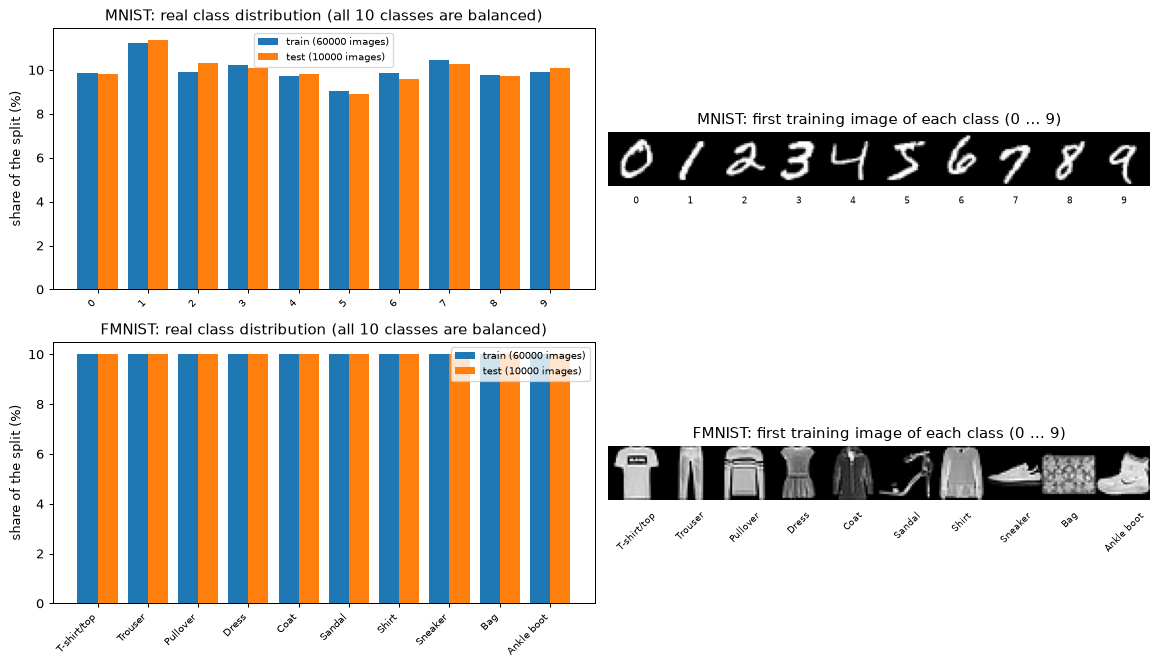

In [6]:
# Real class distributions (bar charts) and one real example image per class
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for r, name in enumerate(DATASETS):
    d = DATA[name]; cls = CLASS_NAMES[name]
    w = 0.4; xs = np.arange(10)
    ax = axes[r, 0]
    ctr, cte = np.bincount(d["ytr"].numpy(), minlength=10), np.bincount(d["yte"].numpy(), minlength=10)
    ax.bar(xs - w / 2, 100 * ctr / ctr.sum(), w, label=f"train ({ctr.sum()} images)", color="tab:blue")
    ax.bar(xs + w / 2, 100 * cte / cte.sum(), w, label=f"test ({cte.sum()} images)", color="tab:orange")
    ax.set_xticks(xs); ax.set_xticklabels(cls, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("share of the split (%)"); ax.set_title(f"{name}: real class distribution (all 10 classes are balanced)"); ax.legend(fontsize=8)
    ax2 = axes[r, 1]; ax2.axis("off")
    tiles = np.zeros((28, 28 * 10))
    for k in range(10):
        i = int((d["ytr"] == k).nonzero()[0][0]); tiles[:, 28 * k:28 * (k + 1)] = d["Xtr"][i].reshape(28, 28).numpy()
    ax2.imshow(tiles, cmap="gray"); ax2.set_title(f"{name}: first training image of each class (0 ... 9)")
    for k in range(10):
        ax2.text(28 * k + 14, 33, cls[k], ha="center", va="top", fontsize=7, rotation=0 if name == "MNIST" else 45)
plt.tight_layout(); plt.show()


The bar charts confirm that both benchmarks are perfectly balanced (10 % per class), so plain accuracy is a fair metric. Next, the 2-D projections of real images:
first from the raw pixels, then from the amplitude-encoded states `|psi> = x / |x|` (784 pixels zero-padded to 1024) that the circuit actually receives.
The paper uses amplitude encoding, not angle encoding, so there is no `[0, pi]` angle rescaling to show.


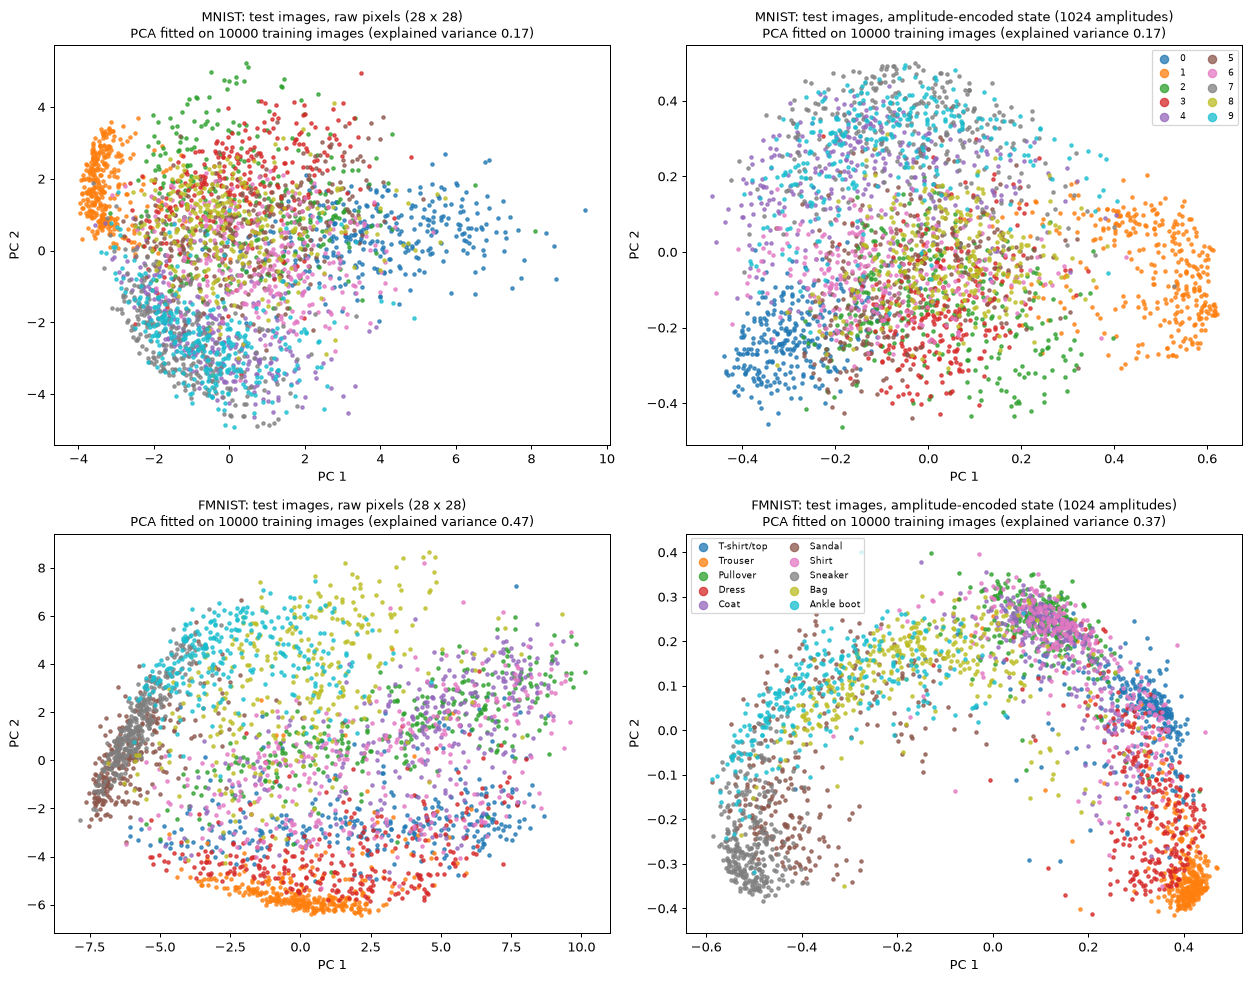

In [7]:
# 2-D scatter of REAL observations coloured by their ground-truth class.
# (1) raw pixel PCA: PCA(2) fitted on a random subset of the TRAINING split only, then applied to test images;
# (2) the same for the states the circuit actually receives: the L2-normalised, zero-padded 1024-vectors (amplitude encoding).
# The paper uses amplitude encoding, not angle encoding, so the [0, pi] rescaling used for angle-encoded models does not apply here.
def encode(x):
    """Amplitude encoding of a batch of flattened images: zero-pad 784 -> 1024 and normalise to unit L2 norm (qml.AmplitudeEmbedding)."""
    x = F.pad(x, (0, 1024 - x.shape[1]))
    return x / x.norm(dim=1, keepdim=True).clamp_min(1e-8)

vis_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for r, name in enumerate(DATASETS):
    d = DATA[name]
    fit_idx = torch.as_tensor(vis_rng.choice(len(d["ytr"]), N_PCA_FIT, replace=False))
    vis_idx = torch.as_tensor(vis_rng.choice(len(d["yte"]), N_VIS, replace=False))
    for c, (title, f) in enumerate([("raw pixels (28 x 28)", lambda z: z), ("amplitude-encoded state (1024 amplitudes)", encode)]):
        pca = PCA(n_components=2, random_state=SEED).fit(f(d["Xtr"][fit_idx]).numpy())
        P = pca.transform(f(d["Xte"][vis_idx]).numpy()); yv = d["yte"][vis_idx].numpy()
        ax = axes[r, c]
        for k in range(10):
            m = yv == k
            ax.scatter(P[m, 0], P[m, 1], s=7, alpha=0.75, color=plt.cm.tab10(k), label=CLASS_NAMES[name][k])
        ax.set_title(f"{name}: test images, {title}\nPCA fitted on {N_PCA_FIT} training images (explained variance {pca.explained_variance_ratio_.sum():.2f})", fontsize=10)
        ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
        if c == 1: ax.legend(markerscale=2.5, fontsize=7, ncol=2, loc="best")
plt.tight_layout(); plt.show()


What to notice: in MNIST the digit classes form fairly separated clouds already in two principal components (1 and 0 are easiest, 4/7/9 overlap),
whereas in FMNIST the footwear classes (sandal, sneaker, ankle boot) form one arm and trousers/dress another, but the tops (T-shirt, pullover, coat, shirt) and bags overlap strongly,
which is consistent with the paper's lower accuracy for FMNIST. Amplitude encoding divides every image by its norm, so the *shape* of the image matters, not its brightness: this is
the representation an attacker perturbs (a perturbation of eps per pixel changes the norm and thereby every amplitude).


## Quantum Circuit Architecture

The classifier is a 10-qubit variational circuit: amplitude embedding of the (padded, normalised) image, then `L` identical-structure layers, each made of a general
rotation `Rot(phi, theta, omega)` on every qubit followed by a chain of CZ gates between neighbouring qubits, and finally the expectation value of Pauli-Z on each qubit.
The `L = 100` layers give 3 000 trainable angles, the `L = 200` layers 6 000. The paper shows the layout in Fig. S1 but gives neither the order of the rotations nor the wiring
of the CZ gates, so both are assumptions (marked `# CHOICE:`). The circuit has no data-encoding parameters at all: the image enters only through the amplitude embedding, which is why
an attack can be computed as a gradient with respect to the pixels of a *fixed* unitary.

**The simulator.** PennyLane's `default.qubit` needs about ten seconds for one image through 100 layers; training and attacking hundreds of images needs something faster.
The next cell contains an exact state-vector simulator written for exactly this circuit (RZ and CZ gates are diagonal and are merged into one phase vector per layer, an RY layer on 10 qubits
is the Kronecker product of two 32 x 32 real matrices). It computes exact expectation values and exact gradients with respect to the circuit angles *and* the pixels.


In [8]:
# ---------------------------------------------------------------------------------------------------------------
# The paper's quantum variational classifier (QVC), as an exact batched state-vector simulator written in PyTorch.
#   |0>^10 --AmplitudeEmbedding(784 pixels, zero-padded to 1024, L2-normalised)--> [ Rot on every qubit ; CZ chain ] x L --> <Z_q>, q = 0..9
# Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi);  CZ(q, q+1) for q = 0..8.  Logit of class q = LOGIT_SCALE * <Z_q>.
# Why a hand-written simulator: PennyLane's default.qubit needs ~10 s per image for a 100-layer circuit; this one runs a whole
# batch of 64 images through 100 layers in ~1 s, with exact gradients with respect to the circuit angles AND the input pixels.
# It is verified against the PennyLane QNode of the next cell (outputs and input gradients agree to ~1e-6) -- that QNode is the
# circuit that is drawn in the "Quantum Circuit Architecture" section.
# Speed trick: RZ gates and CZ gates are diagonal, so all of them between two RY layers merge into one phase vector of 1024 entries;
# an RY layer on 10 qubits is the Kronecker product of two 32 x 32 real matrices (qubits 0-4 and qubits 5-9).
# ---------------------------------------------------------------------------------------------------------------
assert N_QUBITS == 10, "the 5 + 5 qubit block split below is written for 10 qubits"
NQ, DIM = N_QUBITS, 2 ** N_QUBITS
_bits = ((torch.arange(DIM)[:, None] >> (NQ - 1 - torch.arange(NQ))) & 1).float()      # wire 0 = most significant bit (PennyLane convention)
ZSIGN = 1 - 2 * _bits                                                                  # [1024, 10]: eigenvalue of Pauli-Z on wire q in basis state i
CZ_PHASE = (_bits[:, :-1] * _bits[:, 1:]).sum(1) * math.pi                             # CZ chain: phase pi * sum_q b_q b_{q+1}

def _kron_chain(M):
    """M [L, 5, 2, 2] -> [L, 32, 32]: Kronecker product of the five single-qubit matrices (first qubit = most significant)."""
    out = M[:, 0]
    for k in range(1, M.shape[1]):
        n, a = out.shape[0], out.shape[1]
        out = torch.einsum("lab,lcd->lacbd", out, M[:, k]).reshape(n, 2 * a, 2 * a)
    return out

def circuit_blocks(params):
    """params [L, 10, 3] = (phi, theta, omega) of every Rot gate -> RY blocks A, B and the merged diagonal phases (cos, sin)."""
    phi, th, om = params[..., 0], params[..., 1], params[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    ry = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)           # [L, 10, 2, 2]
    A, B = _kron_chain(ry[:, :5]), _kron_chain(ry[:, 5:])
    ph_phi, ph_om = -0.5 * (phi @ ZSIGN.T), -0.5 * (om @ ZSIGN.T)                      # RZ(a) = diag(e^{-ia/2}, e^{+ia/2})
    ph_mid = ph_om + CZ_PHASE                                                          # RZ(omega_l) then the CZ chain, after RY_l
    ph_all = torch.cat([ph_phi[:1], ph_mid[:-1] + ph_phi[1:], ph_mid[-1:]], 0)         # phase applied before RY_0 ... after RY_{L-1}
    return A, B, torch.cos(ph_all).reshape(-1, 32, 32), torch.sin(ph_all).reshape(-1, 32, 32)

def run_circuit(psi, params):
    """psi: real amplitude vectors [n, 1024] -> X [2, n, 32, 32] with X[0] = Re(U psi), X[1] = Im(U psi) (differentiable)."""
    A, B, C, S_ = circuit_blocks(params)
    n = psi.shape[0]
    x = psi.reshape(n, 32, 32)
    X = torch.stack([x * C[0], x * S_[0]], 0)
    for l in range(A.shape[0]):
        X = (A[l] @ X) @ B[l].T                                                        # RY layer on qubits 0-4 (left) and 5-9 (right)
        X = torch.stack([X[0] * C[l + 1] - X[1] * S_[l + 1], X[0] * S_[l + 1] + X[1] * C[l + 1]], 0)   # merged RZ / CZ phases
    return X

def expz_from_state(X):
    """<Z_q> for q = 0..9 from the simulated state."""
    return (X[0] ** 2 + X[1] ** 2).reshape(X.shape[1], DIM) @ ZSIGN

@torch.no_grad()
def build_unitary(params):
    """The whole L-layer circuit as one 1024 x 1024 complex matrix (stored as [2, 1024, 1024]; row k = U e_k).
    The circuit does not depend on the data, so after training every attack / evaluation is two matrix products."""
    X = run_circuit(torch.eye(DIM), params)
    return X.reshape(2, DIM, DIM)

def qvc_logits(x, U):
    """Logits of the trained classifier for a batch of images x [n, 784] in [0, 1] (differentiable with respect to x)."""
    psi = encode(x)
    re, im = psi @ U[0], psi @ U[1]
    return LOGIT_SCALE * ((re ** 2 + im ** 2) @ ZSIGN)

def acc_of(logit_fn, X, y, bs=1000):
    with torch.no_grad():
        return float(np.mean(np.concatenate([(logit_fn(X[i:i + bs]).argmax(1) == y[i:i + bs]).numpy() for i in range(0, len(y), bs)])))

n_par = lambda L: L * NQ * 3
print("simulator ready; trainable parameters:", {f"QVC{L}": n_par(L) for L in LAYERS})


simulator ready; trainable parameters: {'QVC100': 3000, 'QVC200': 6000}


**Equivalence to the PennyLane circuit.** The next cell defines the circuit as a PennyLane QNode (the object that is drawn below) and asserts that the simulator reproduces its
`<Z>` outputs, and the gradient of the cross-entropy with respect to the input pixels, for random circuits of depth 2 and for every depth used in this notebook; the same check is repeated
with the *trained* circuits after training. The assertion fails the notebook if the two ever disagree by more than 2e-4 in the outputs or 1e-3 (relative) in the gradients.


In [9]:
# The PennyLane QNode of the paper's circuit (this is the circuit object that is drawn below and that the simulator is checked against)
def make_qnode(n_layers):
    dev = qml.device("default.qubit", wires=NQ)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def qnode(x, params):
        qml.AmplitudeEmbedding(x, wires=range(NQ), pad_with=0.0, normalize=True)            # 784 pixels -> 1024 amplitudes
        for l in range(n_layers):                                                           # CHOICE: Rot = RZ RY RZ (paper figure: Rz, Rz, Ry rotations)
            for q in range(NQ):
                qml.Rot(params[l, q, 0], params[l, q, 1], params[l, q, 2], wires=q)
            for q in range(NQ - 1):                                                         # CHOICE: CZ between neighbouring qubits, open chain
                qml.CZ(wires=[q, q + 1])
        return [qml.expval(qml.PauliZ(q)) for q in range(NQ)]
    return qnode

def check_against_pennylane(params, x, y, tol=2e-4, verbose=True):
    """Compare simulator and PennyLane QNode (double precision): <Z> outputs and the gradient of the cross-entropy with respect to the pixels."""
    L = params.shape[0]; qn = make_qnode(L)
    xp = x.double().clone().requires_grad_(True)
    z_pl = torch.stack(qn(xp, params.double()), -1)                                          # [n, 10]
    F.cross_entropy(LOGIT_SCALE * z_pl, y).backward()
    xs = x.clone().requires_grad_(True)
    z_sim = expz_from_state(run_circuit(encode(xs), params.float()))
    F.cross_entropy(LOGIT_SCALE * z_sim, y).backward()
    U = build_unitary(params.float())
    xu = x.clone().requires_grad_(True)
    lg_u = qvc_logits(xu, U); F.cross_entropy(lg_u, y).backward()
    d_out = (z_pl - z_sim).abs().max().item(); d_unit = (LOGIT_SCALE * z_pl - lg_u).abs().max().item() / LOGIT_SCALE
    gscale = xp.grad.abs().max().item()
    d_grad = (xp.grad - xs.grad.double()).abs().max().item() / gscale
    d_grad_u = (xp.grad - xu.grad.double()).abs().max().item() / gscale
    if verbose:
        print(f"L = {L:3d}: max |<Z> PennyLane - simulator| = {d_out:.1e}; via 1024x1024 unitary = {d_unit:.1e}; "
              f"relative max |d loss / d pixel| difference = {d_grad:.1e} (simulator), {d_grad_u:.1e} (unitary)")
    assert d_out < tol and d_unit < tol and d_grad < 1e-3 and d_grad_u < 1e-3, "simulator disagrees with the PennyLane QNode"
    return d_out, d_grad

g_chk = torch.Generator().manual_seed(SEED)
x_chk = DATA["MNIST"]["Xte"][:2]; y_chk = DATA["MNIST"]["yte"][:2]
t0 = time.time()
for L in (2,) + tuple(LAYERS):
    check_against_pennylane(2 * math.pi * torch.rand(L, NQ, 3, generator=g_chk), x_chk, y_chk)
print(f"all equivalence assertions passed ({time.time() - t0:.0f} s): the fast simulator IS the PennyLane circuit")


L =   2: max |<Z> PennyLane - simulator| = 1.9e-07; via 1024x1024 unitary = 1.4e-07; relative max |d loss / d pixel| difference = 9.3e-07 (simulator), 7.8e-07 (unitary)


L = 100: max |<Z> PennyLane - simulator| = 1.0e-06; via 1024x1024 unitary = 1.1e-06; relative max |d loss / d pixel| difference = 1.3e-05 (simulator), 1.2e-05 (unitary)


L = 200: max |<Z> PennyLane - simulator| = 1.3e-06; via 1024x1024 unitary = 1.4e-06; relative max |d loss / d pixel| difference = 1.9e-05 (simulator), 2.1e-05 (unitary)
all equivalence assertions passed (60 s): the fast simulator IS the PennyLane circuit


**The circuit that is executed.** A 100-layer circuit has 1 900 gates and would not be legible, so the drawing shows the first two layers of the very QNode that the simulator is checked
against (`make_qnode(2)`); the full circuit is this block repeated `L` times. The table gives the qubit count, depth and parameter count of the full-depth QNodes
(`qml.specs`). Rotation angles in the drawing are random illustration values; the trained circuits have the identical structure.


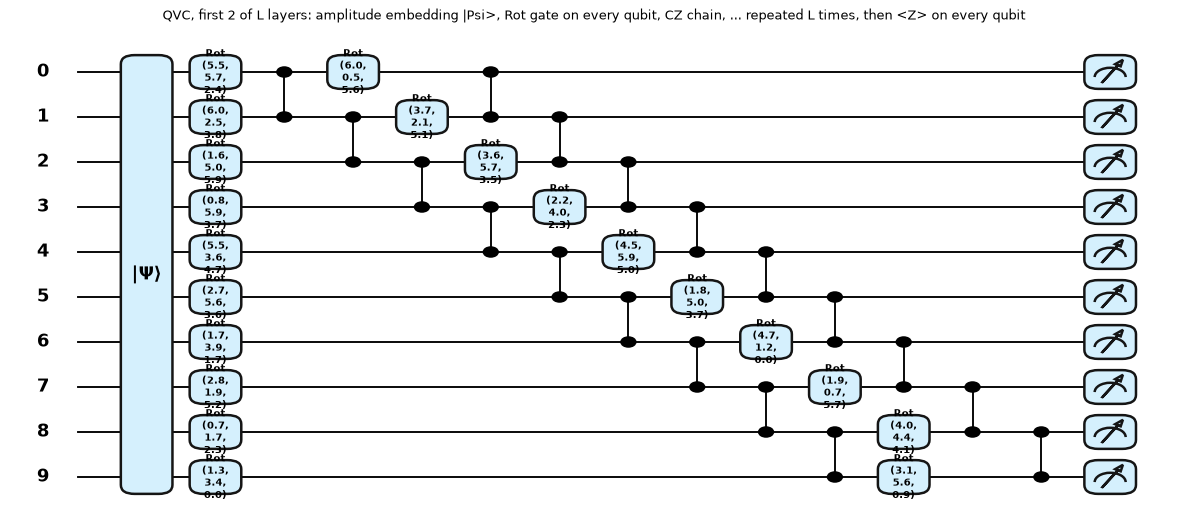

,qubits,layers L,depth (qml.specs),total gates,Rot gates,CZ gates,trainable parameters,data-encoding parameters,measurements
model,,,,,,,,,
QVC100,10,100,308,1901,1000,900,3000,0,<Z> on 10 qubits
QVC200,10,200,608,3801,2000,1800,6000,0,<Z> on 10 qubits


Assumptions (the paper omits these details): Rot = RZ(omega) RY(theta) RZ(phi) (the paper's figure lists Rz, Rz, Ry rotations); CZ gates join neighbouring qubits 0-1, 1-2, ..., 8-9 (open chain, no wrap-around); the 784 pixels are zero-padded to 1024 amplitudes and L2-normalised; logit_q = 10 * <Z_q>, class = argmax over the 10 qubits; 3 angles x 10 qubits x L layers trainable parameters (the paper states only '10 qubits, depth 100/200 layers').


In [10]:
# Draw the PennyLane QNode that is executed (first two layers shown; the full circuit repeats this block L times), then
# print qubits / depth / trainable parameters of the full-depth QNodes, obtained from qml.specs of the same QNode builder.
x_demo = DATA["MNIST"]["Xte"][0]
p_demo = (2 * math.pi * torch.rand(2, NQ, 3, generator=torch.Generator().manual_seed(SEED))).double()
fig, ax = qml.draw_mpl(make_qnode(2), decimals=1, style="pennylane")(x_demo.double(), p_demo)
fig.set_size_inches(13, 5.5)
ax.set_title("QVC, first 2 of L layers: amplitude embedding |Psi>, Rot gate on every qubit, CZ chain, ... repeated L times, then <Z> on every qubit", fontsize=10)
plt.show()

rows = []
for L in LAYERS:
    pl_p = torch.rand(L, NQ, 3).double()
    sp = qml.specs(make_qnode(L))(x_demo.double(), pl_p)
    r = sp.resources
    rows.append({"model": f"QVC{L}", "qubits": sp.num_device_wires, "layers L": L, "depth (qml.specs)": r.depth, "total gates": r.num_gates,
                 "Rot gates": r.gate_types.get("Rot", 0), "CZ gates": r.gate_types.get("CZ", 0), "trainable parameters": 3 * NQ * L,
                 "data-encoding parameters": 0, "measurements": f"<Z> on {NQ} qubits"})
display(pd.DataFrame(rows).set_index("model"))
print("Assumptions (the paper omits these details): Rot = RZ(omega) RY(theta) RZ(phi) (the paper's figure lists Rz, Rz, Ry rotations); CZ gates join neighbouring qubits "
      "0-1, 1-2, ..., 8-9 (open chain, no wrap-around); the 784 pixels are zero-padded to 1024 amplitudes and L2-normalised; logit_q = 10 * <Z_q>, "
      "class = argmax over the 10 qubits; 3 angles x 10 qubits x L layers trainable parameters (the paper states only '10 qubits, depth 100/200 layers').")


## 2. Training the quantum classifiers (QVC100 and QVC200)

Each classifier is trained with Adam on the cross-entropy of the ten scores `10 * <Z_q>` (the scale is only a rescaling of the logits, because `<Z>` lies in `[-1, 1]`).
Mini-batches are distinct training images, nothing is tuned on test images (all hyper-parameters are fixed in the configuration cell before any test image is used), and the test images only
appear in the accuracy reported after training. After training, the whole circuit is multiplied out into one 1024 x 1024 unitary (it does not depend on the data), which makes every later attack and
evaluation two matrix products instead of a 100-layer simulation; the cell checks that this matrix is unitary.


In [11]:
# Training of the quantum variational classifiers: Adam on the cross-entropy of 10 * <Z_q>, no data other than the training split is touched.
TEST_PERM = {n: torch.as_tensor(np.random.default_rng(SEED).permutation(len(DATA[n]["yte"]))) for n in DATASETS}   # fixed test subsets (clean / attacked)
QVC = {}      # (dataset, L) -> dict(params, U, hist, seconds, clean_acc)

def init_params(L, seed):
    g = torch.Generator().manual_seed(seed)
    return (2 * math.pi * torch.rand(L, NQ, 3, generator=g)).requires_grad_(True)       # CHOICE: angles uniform in [0, 2 pi) (paper: not stated)

def train_qvc(ds, L, seed=SEED):
    X, y = DATA[ds]["Xtr"], DATA[ds]["ytr"]
    order = torch.randperm(len(y), generator=torch.Generator().manual_seed(seed))[:TRAIN_STEPS * BATCH]     # distinct training images, no repeats
    p = init_params(L, seed + L)
    opt = torch.optim.Adam([p], lr=LR)
    hist, t0 = [], time.time()
    for s in range(TRAIN_STEPS):
        idx = order[s * BATCH:(s + 1) * BATCH]
        logits = LOGIT_SCALE * expz_from_state(run_circuit(encode(X[idx]), p))
        loss = F.cross_entropy(logits, y[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        hist.append((loss.item(), (logits.argmax(1) == y[idx]).float().mean().item()))
        if s % 20 == 0 or s == TRAIN_STEPS - 1:
            print(f"  [{ds} QVC{L}] step {s:3d}/{TRAIN_STEPS}  batch loss {hist[-1][0]:.3f}  batch acc {hist[-1][1]:.2f}  ({time.time() - t0:.0f} s)", flush=True)
    return p.detach(), hist, time.time() - t0

def fit_dataset(ds):
    for L in LAYERS:
        params, hist, secs = train_qvc(ds, L)
        U = build_unitary(params)
        err = ((U[0] ** 2 + U[1] ** 2).sum(1) - 1).abs().max().item()
        assert err < 1e-3, f"circuit matrix is not unitary (row-norm error {err})"
        te = TEST_PERM[ds][:N_CLEAN_TEST]
        acc = acc_of(lambda z: qvc_logits(z, U), DATA[ds]["Xte"][te], DATA[ds]["yte"][te])
        QVC[(ds, L)] = dict(params=params, U=U, hist=hist, seconds=secs, clean_acc=acc)
        TIMES[f"train {ds} QVC{L}"] = secs
        print(f"{ds} QVC{L}: trained in {secs / 60:.1f} min, clean test accuracy {100 * acc:.1f} % on {N_CLEAN_TEST} test images (unitarity error {err:.1e})\n")


In [12]:
fit_dataset("MNIST")


  [MNIST QVC100] step   0/100  batch loss 2.377  batch acc 0.11  (4 s)


  [MNIST QVC100] step  20/100  batch loss 1.485  batch acc 0.62  (70 s)


  [MNIST QVC100] step  40/100  batch loss 1.274  batch acc 0.77  (141 s)


  [MNIST QVC100] step  60/100  batch loss 1.202  batch acc 0.73  (216 s)


  [MNIST QVC100] step  80/100  batch loss 1.007  batch acc 0.89  (279 s)


...

  [MNIST QVC200] step  40/100  batch loss 1.364  batch acc 0.67  (423 s)


  [MNIST QVC200] step  60/100  batch loss 1.211  batch acc 0.77  (540 s)


  [MNIST QVC200] step  80/100  batch loss 0.986  batch acc 0.78  (624 s)


  [MNIST QVC200] step  99/100  batch loss 1.003  batch acc 0.80  (708 s)


MNIST QVC200: trained in 11.8 min, clean test accuracy 82.8 % on 10000 test images (unitarity error 1.7e-06)



In [13]:
fit_dataset("FMNIST")


  [FMNIST QVC100] step   0/100  batch loss 2.306  batch acc 0.16  (2 s)


  [FMNIST QVC100] step  20/100  batch loss 1.453  batch acc 0.62  (28 s)


  [FMNIST QVC100] step  40/100  batch loss 1.178  batch acc 0.70  (55 s)


  [FMNIST QVC100] step  60/100  batch loss 1.062  batch acc 0.73  (83 s)


  [FMNIST QVC100] step  80/100  batch loss 1.057  batch acc 0.72  (131 s)


...

  [FMNIST QVC200] step  40/100  batch loss 1.370  batch acc 0.55  (133 s)


  [FMNIST QVC200] step  60/100  batch loss 1.046  batch acc 0.78  (209 s)


  [FMNIST QVC200] step  80/100  batch loss 1.073  batch acc 0.67  (295 s)


  [FMNIST QVC200] step  99/100  batch loss 0.998  batch acc 0.73  (383 s)


FMNIST QVC200: trained in 6.4 min, clean test accuracy 70.2 % on 10000 test images (unitarity error 7.2e-07)



The loss curves show how quickly the deep circuit learns from a random start. The table compares the clean accuracies with the numbers the paper quotes for its first panel (85 % / 70 % / 89 %); the last cell
re-checks the *trained* circuits against the PennyLane QNode.


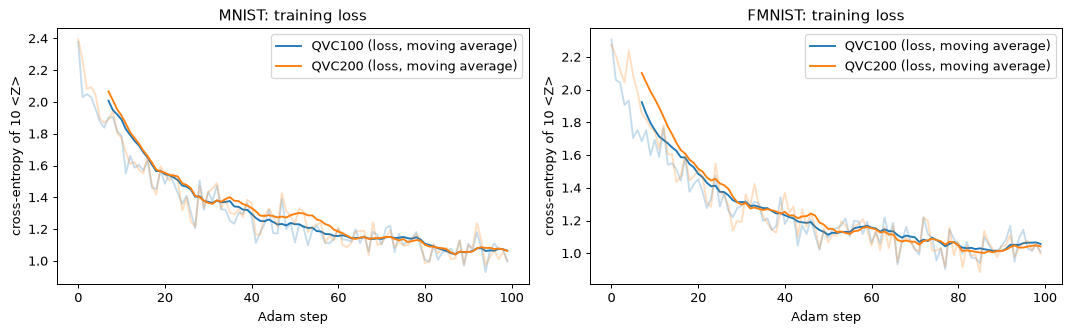

,dataset,model,parameters,clean test acc (%),paper (%),train time (min)
0,MNIST,QVC100,3000,82.7,85,6.1
1,MNIST,QVC200,6000,82.8,89,11.8
2,FMNIST,QVC100,3000,69.7,70,3.0
3,FMNIST,QVC200,6000,70.2,not reported,6.4


L = 100: max |<Z> PennyLane - simulator| = 7.9e-07; via 1024x1024 unitary = 8.9e-07; relative max |d loss / d pixel| difference = 1.0e-05 (simulator), 1.1e-05 (unitary)


L = 200: max |<Z> PennyLane - simulator| = 1.1e-06; via 1024x1024 unitary = 1.2e-06; relative max |d loss / d pixel| difference = 1.7e-05 (simulator), 1.6e-05 (unitary)
trained circuits agree with the PennyLane QNode (outputs and input gradients)


In [14]:
# Training curves, clean accuracy table and a second equivalence check on the TRAINED circuits (simulator vs PennyLane QNode)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, ds in zip(axes, DATASETS):
    for L in LAYERS:
        h = np.array(QVC[(ds, L)]["hist"]); k = max(len(h) // 12, 1)
        sm = np.convolve(h[:, 0], np.ones(k) / k, mode="valid")
        ax.plot(h[:, 0], alpha=0.25, color="C0" if L == LAYERS[0] else "C1")
        ax.plot(np.arange(len(sm)) + k - 1, sm, color="C0" if L == LAYERS[0] else "C1", label=f"QVC{L} (loss, moving average)")
    ax.set_xlabel("Adam step"); ax.set_ylabel("cross-entropy of 10 <Z>"); ax.set_title(f"{ds}: training loss"); ax.legend()
plt.tight_layout(); plt.show()

PAPER_CLEAN = {("MNIST", LAYERS[0]): 85, ("FMNIST", LAYERS[0]): 70, ("MNIST", LAYERS[1]): 89}
rows = [{"dataset": ds, "model": f"QVC{L}", "parameters": n_par(L), "clean test acc (%)": round(100 * QVC[(ds, L)]["clean_acc"], 1),
         "paper (%)": PAPER_CLEAN.get((ds, L), "not reported"), "train time (min)": round(QVC[(ds, L)]["seconds"] / 60, 1)}
        for ds in DATASETS for L in LAYERS]
display(pd.DataFrame(rows))

xb, yb = DATA["MNIST"]["Xte"][TEST_PERM["MNIST"][:2]], DATA["MNIST"]["yte"][TEST_PERM["MNIST"][:2]]
for L in LAYERS:
    check_against_pennylane(QVC[("MNIST", L)]["params"], xb, yb)
print("trained circuits agree with the PennyLane QNode (outputs and input gradients)")


## 3. Quantum adversarial attacks: FGSM and PGD, white-box and black-box

Both attacks are untargeted and maximise the cross-entropy of the true label with respect to the input pixels, using the gradient of the *quantum* circuit (here exact back-propagation through the
simulator, which equals the parameter-shift gradients of the paper for the noiseless circuit - asserted above). **FGSM** takes one step `x + eps * sign(grad)`; **PGD** takes several smaller steps
and projects back on the `eps`-ball around the clean image after each one. Attacks are always crafted on QVC100. In the **white-box** setting QVC100 itself classifies the adversarial images; in the **black-box**
(transfer) setting QVC200, a deeper circuit trained from a different random start, classifies them. The cell checks that every adversarial image stays within `eps` of the original and within `[0, 1]`.


In [15]:
def input_grad(logit_fn, x, y):
    """Gradient of the summed cross-entropy with respect to the input pixels (exact, by back-propagation through the simulator)."""
    x = x.clone().requires_grad_(True)
    g, = torch.autograd.grad(F.cross_entropy(logit_fn(x), y, reduction="sum"), x)
    return g

def fgsm(logit_fn, x, y, eps, chunk=500):
    """FGSM (paper eq. 2): x_adv = x + eps * sign(grad_x L).  CHOICE: pixels are clipped back to the valid range [0, 1]."""
    if eps == 0:
        return x.clone()
    out = [(x[i:i + chunk] + eps * input_grad(logit_fn, x[i:i + chunk], y[i:i + chunk]).sign()).clamp(0, 1).detach() for i in range(0, len(x), chunk)]
    return torch.cat(out)

def pgd(logit_fn, x, y, eps, steps=None, chunk=500):
    """PGD (paper eq. 3-4): steps of size alpha along sign(grad), each followed by a projection on the eps-ball around the clean image.
    CHOICE: no random start, alpha = PGD_ALPHA_FACTOR * eps / steps, clipped to [0, 1]."""
    steps = steps or PGD_STEPS
    if eps == 0:
        return x.clone()
    alpha, out = PGD_ALPHA_FACTOR * eps / steps, []
    for i in range(0, len(x), chunk):
        x0, yy = x[i:i + chunk], y[i:i + chunk]; xa = x0.clone()
        for _ in range(steps):
            xa = xa + alpha * input_grad(logit_fn, xa, yy).sign()
            xa = torch.min(torch.max(xa, x0 - eps), x0 + eps).clamp(0, 1).detach()
        out.append(xa)
    return torch.cat(out)

ATTACKS = {"FGSM": fgsm, "PGD": pgd}
ATT = {ds: dict(X=DATA[ds]["Xte"][TEST_PERM[ds][:N_ATT]], y=DATA[ds]["yte"][TEST_PERM[ds][:N_ATT]]) for ds in DATASETS}   # the attacked test images
ADV = {}      # (dataset, attack, eps) -> adversarial images crafted on the attacker model (QVC100): [N_ATT, 784]
ACC = {}      # (dataset, attack, scenario, eps, "adv" | "rec") -> accuracy;  scenario "white" = QVC100 attacked and evaluated, "black" = evaluated on QVC200

def logit_fn_of(ds, L):
    U = QVC[(ds, L)]["U"]
    return lambda z: qvc_logits(z, U)

def craft_all(ds):
    f_att = logit_fn_of(ds, LAYERS[0]); X, y = ATT[ds]["X"], ATT[ds]["y"]
    t0 = time.time()
    for atk, fn in ATTACKS.items():
        for eps in EPS_LIST:
            ADV[(ds, atk, eps)] = fn(f_att, X, y, eps)
            for scen, L in (("white", LAYERS[0]), ("black", LAYERS[1])):
                ACC[(ds, atk, scen, eps, "adv")] = acc_of(logit_fn_of(ds, L), ADV[(ds, atk, eps)], y)
        print(f"  {ds} {atk}: " + ", ".join(f"eps {e:.2f}: WB {100 * ACC[(ds, atk, 'white', e, 'adv')]:.0f}% / BB {100 * ACC[(ds, atk, 'black', e, 'adv')]:.0f}%" for e in EPS_LIST), flush=True)
    TIMES[f"attacks {ds}"] = time.time() - t0
    print(f"  {ds}: attacks crafted on {NAME_A} in {(time.time() - t0) / 60:.1f} min")

for ds in DATASETS:
    craft_all(ds)

lin = {(ds, atk, e): (ADV[(ds, atk, e)] - ATT[ds]["X"]).abs().max().item() for ds in DATASETS for atk in ATTACKS for e in EPS_LIST}
assert all(v <= e + 1e-5 for (ds, atk, e), v in lin.items()), "an attack left the eps-ball"
print("all adversarial images stay inside the L-infinity eps-ball and the pixel range [0, 1] (max |x_adv - x| <= eps checked)")


  MNIST FGSM: eps 0.00: WB 84% / BB 84%, eps 0.05: WB 43% / BB 80%, eps 0.10: WB 10% / BB 74%, eps 0.15: WB 0% / BB 67%, eps 0.20: WB 0% / BB 59%, eps 0.25: WB 0% / BB 48%, eps 0.30: WB 0% / BB 36%


  MNIST PGD: eps 0.00: WB 84% / BB 84%, eps 0.05: WB 42% / BB 80%, eps 0.10: WB 8% / BB 73%, eps 0.15: WB 0% / BB 67%, eps 0.20: WB 0% / BB 57%, eps 0.25: WB 0% / BB 45%, eps 0.30: WB 0% / BB 33%


  MNIST: attacks crafted on QVC100 in 0.7 min


  FMNIST FGSM: eps 0.00: WB 72% / BB 71%, eps 0.05: WB 25% / BB 65%, eps 0.10: WB 5% / BB 57%, eps 0.15: WB 0% / BB 50%, eps 0.20: WB 0% / BB 42%, eps 0.25: WB 0% / BB 36%, eps 0.30: WB 0% / BB 30%


  FMNIST PGD: eps 0.00: WB 72% / BB 71%, eps 0.05: WB 24% / BB 65%, eps 0.10: WB 4% / BB 55%, eps 0.15: WB 0% / BB 48%, eps 0.20: WB 0% / BB 39%, eps 0.25: WB 0% / BB 31%, eps 0.30: WB 0% / BB 23%


  FMNIST: attacks crafted on QVC100 in 1.1 min


all adversarial images stay inside the L-infinity eps-ball and the pixel range [0, 1] (max |x_adv - x| <= eps checked)


## 4. The classical autoencoder ("distillation")

The autoencoder is a small CNN: two stride-2 convolutions (16 and 32 filters) compress a 28 x 28 image to 32 x 7 x 7, a fully connected layer reduces it to a 20-number latent vector, and a mirrored decoder with two
transposed convolutions and a Sigmoid reconstructs a 28 x 28 image. It is trained with the mean squared error to map **attacked image -> clean image** (Adam 0.001, 20 epochs in full mode). Because the
bottleneck keeps only 20 numbers, it can store the shape of a digit or garment but not the high-frequency, off-manifold pattern of an adversarial perturbation. The first cell below builds the
training pairs from the *training* images, attacked with QVC100 (the attack mixture is our choice, see the table at the top), and trains the autoencoder (one per dataset, several seeds in full mode).


In [16]:
class AutoEncoder(nn.Module):
    """Paper S4: encoder Conv(1->16, 3x3, stride 2, pad 1) - Conv(16->32, 3x3, stride 2, pad 1) - flatten (1568) - FC -> 20;
    decoder FC 20 -> 1568 - reshape 32x7x7 - ConvT(32->16) - ConvT(16->1) - Sigmoid. ReLU in the intermediate layers.
    CHOICE: no activation on the 20-dimensional latent layer (the paper's activation 'sigma' of Eq. 9 is unspecified; with a ReLU there the
    short training runs of this notebook collapsed to a constant output image because of dead latent units)."""
    def __init__(self, latent=20):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, 16, 3, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 3, 2, 1), nn.ReLU(), nn.Flatten(),
                                 nn.Linear(32 * 7 * 7, latent))
        self.dec_fc = nn.Sequential(nn.Linear(latent, 32 * 7 * 7), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(32, 16, 3, 2, 1, output_padding=1), nn.ReLU(),     # CHOICE: output_padding=1 gives 7 -> 14 -> 28
                                 nn.ConvTranspose2d(16, 1, 3, 2, 1, output_padding=1), nn.Sigmoid())
    def forward(self, x):                                  # x: [n, 784] -> reconstruction [n, 784]
        z = self.enc(x.reshape(-1, 1, 28, 28))
        return self.dec(self.dec_fc(z).reshape(-1, 32, 7, 7)).reshape(-1, 784)

ae_probe = AutoEncoder()
shapes = [tuple(ae_probe.enc[:i](torch.zeros(1, 1, 28, 28)).shape) for i in (1, 3, 5, 6)]   # after conv1 / conv2 / flatten / latent layer
print("encoder feature-map shapes after conv1 / conv2 / flatten / latent:", shapes, "| parameters:", sum(p.numel() for p in ae_probe.parameters()))
assert shapes[1] == (1, 32, 7, 7) and shapes[3] == (1, 20) and ae_probe(torch.zeros(1, 784)).shape == (1, 784)

def make_ae_trainset(ds):
    """Pairs (attacked image, clean image) from the TRAINING split, attacks crafted on QVC100: clean + FGSM + PGD at every eps, equal shares.
    CHOICE: the paper does not say which eps / attack mixture the autoencoder sees; one autoencoder per dataset sees all of them."""
    d = DATA[ds]; f_att = logit_fn_of(ds, LAYERS[0])
    perm = torch.randperm(len(d["ytr"]), generator=torch.Generator().manual_seed(SEED + 1))[:N_AE_TRAIN]
    X, y = d["Xtr"][perm], d["ytr"][perm]
    combos = [("clean", 0.0)] + [(a, e) for a in ATTACKS for e in EPS_LIST[1:]]
    Xadv = X.clone()
    for (a, e), idx in zip(combos, np.array_split(np.arange(N_AE_TRAIN), len(combos))):
        if a != "clean":
            Xadv[idx] = ATTACKS[a](f_att, X[idx], y[idx], e)
    return Xadv, X

def train_ae(Xadv, Xcl, seed):
    torch.manual_seed(seed)
    ae = AutoEncoder(); opt = torch.optim.Adam(ae.parameters(), lr=AE_LR)
    g = torch.Generator().manual_seed(seed); hist = []
    for ep in range(AE_EPOCHS):
        order = torch.randperm(len(Xcl), generator=g); tot = 0.0
        for i in range(0, len(order), AE_BS):
            b = order[i:i + AE_BS]
            loss = F.mse_loss(ae(Xadv[b]), Xcl[b])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        hist.append(tot / len(order))
    return ae.eval(), hist

AE = {}       # dataset -> list of autoencoders (one per seed; the first one is used in the figures)
AE_HIST = {}
for ds in DATASETS:
    t0 = time.time()
    Xadv_tr, Xcl_tr = make_ae_trainset(ds)
    AE[ds], AE_HIST[ds] = [], []
    for k in range(AE_SEEDS):
        ae, h = train_ae(Xadv_tr, Xcl_tr, SEED + k); AE[ds].append(ae); AE_HIST[ds].append(h)
    TIMES[f"autoencoder {ds}"] = time.time() - t0
    print(f"{ds}: {AE_SEEDS} autoencoder(s) trained on {len(Xcl_tr)} attacked/clean pairs for {AE_EPOCHS} epochs in {(time.time() - t0) / 60:.1f} min; "
          f"final MSE {AE_HIST[ds][0][-1]:.4f} (first epoch {AE_HIST[ds][0][0]:.4f})")

@torch.no_grad()
def purify(ds, X, k=0):
    return AE[ds][k](X)


encoder feature-map shapes after conv1 / conv2 / flatten / latent:

 [(1, 16, 14, 14), (1, 32, 7, 7), (1, 1568), (1, 20)] | parameters: 73877


MNIST: 2 autoencoder(s) trained on 5200 attacked/clean pairs for 20 epochs in 7.8 min; final MSE 0.0134 (first epoch 0.1152)


FMNIST: 2 autoencoder(s) trained on 5200 attacked/clean pairs for 20 epochs in 6.5 min; final MSE 0.0157 (first epoch 0.1088)


### Fig. 2 analogue: clean, adversarial and purified images

One test image per class at the strongest attack (`eps = 0.3`): top row clean, then for FGSM and PGD the adversarial image and the autoencoder's reconstruction. The title of every tile is the class
predicted by the attacked circuit (QVC100): green = correct, red = wrong.


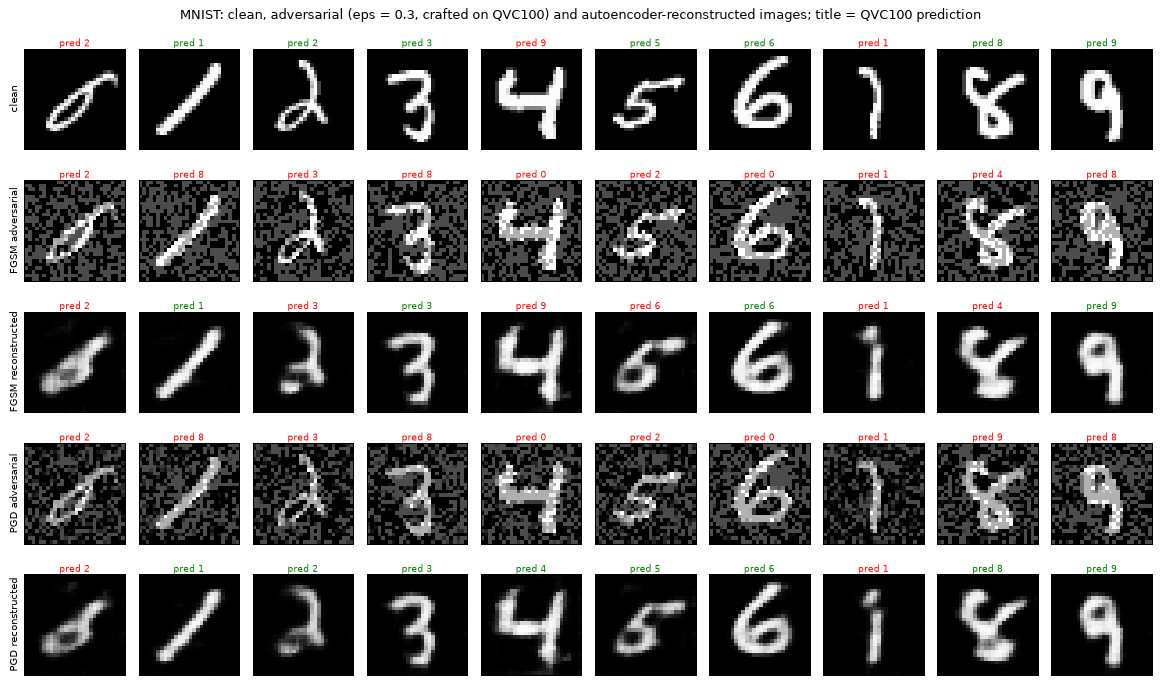

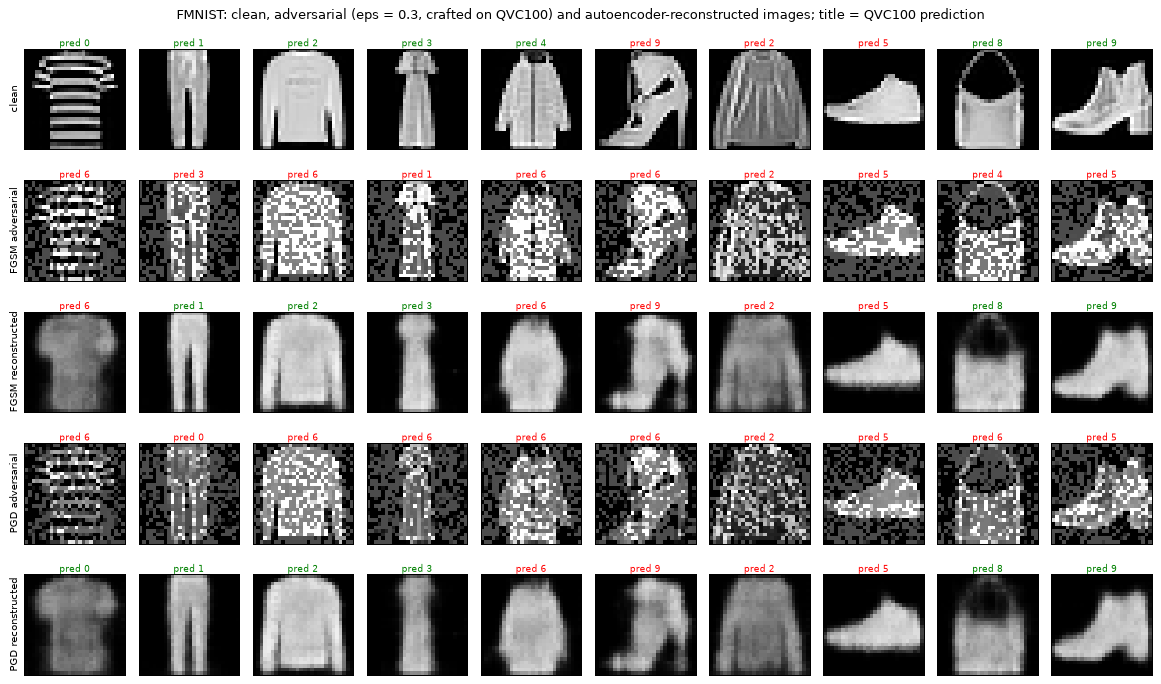

In [17]:
# Fig. 2 analogue: clean / adversarial / reconstructed images at eps = 0.3 (one test image per class; red title = the attacked QVC misclassifies it)
EPS_SHOW = EPS_LIST[-1]
for ds in DATASETS:
    X, y = ATT[ds]["X"], ATT[ds]["y"]
    idx = [int((y == k).nonzero()[0][0]) for k in range(10)]
    f = logit_fn_of(ds, LAYERS[0])
    rows = [("clean", X[idx])]
    for atk in ATTACKS:
        adv = ADV[(ds, atk, EPS_SHOW)][idx]
        rows += [(f"{atk} adversarial", adv), (f"{atk} reconstructed", purify(ds, adv))]
    fig, axes = plt.subplots(len(rows), 10, figsize=(13, 1.45 * len(rows) + 0.6))
    with torch.no_grad():
        for r, (name, imgs) in enumerate(rows):
            pred = f(imgs).argmax(1)
            for k in range(10):
                ax = axes[r, k]; ax.imshow(imgs[k].reshape(28, 28), cmap="gray", vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
                ax.set_title(f"pred {int(pred[k])}", fontsize=7, color="green" if pred[k] == k else "red", pad=2)
                if k == 0: ax.set_ylabel(name, fontsize=8)
    fig.suptitle(f"{ds}: clean, adversarial (eps = {EPS_SHOW}, crafted on {NAME_A}) and autoencoder-reconstructed images; title = {NAME_A} prediction", fontsize=10)
    plt.tight_layout(); plt.show()


## 5. Results: accuracy under attack and after the defence (Fig. 3 and Fig. S2)

For every dataset, attack, scenario and attack strength the accuracy of the quantum classifier is measured on (a) the adversarial images and (b) the same images after the autoencoder. At `eps = 0` the "reconstructed"
point is the accuracy on clean images that went through the autoencoder (the paper also reports this point). Black stars mark the few numbers the paper quotes in its text.


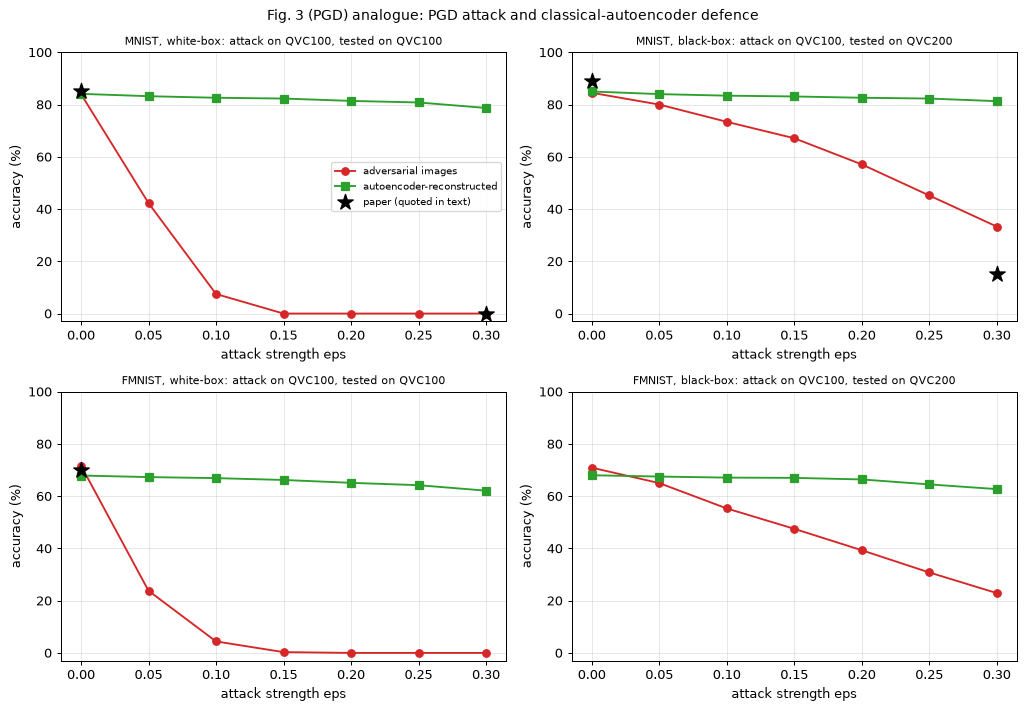

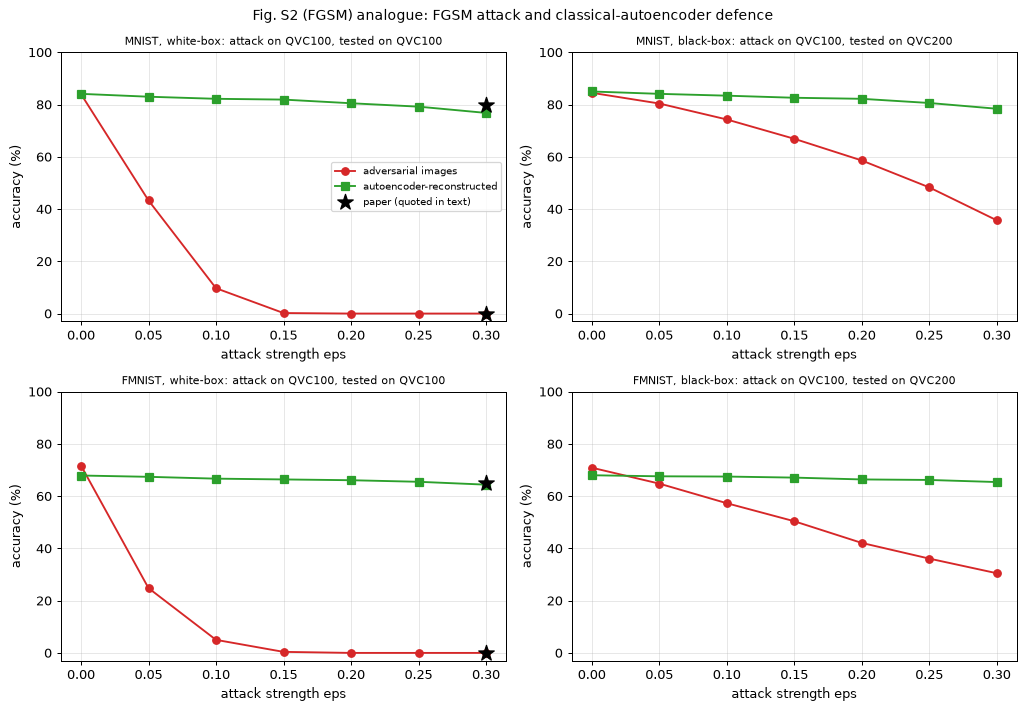

accuracy (%) on adversarial images (adv) and on reconstructed images (rec) per attack strength eps;  eps = 0 'rec' = clean images through the autoencoder


adv 0.00  adv 0.05  adv 0.10  adv 0.15  adv 0.20  adv 0.25  adv 0.30  rec 0.00  rec 0.05  rec 0.10  rec 0.15  rec 0.20  rec 0.25  rec 0.30
dataset attack scenario                                                                                                                                                      
MNIST   FGSM   white-box (QVC100)      84.0      43.3       9.7       0.2       0.0       0.0       0.0      84.1      83.0      82.2      81.9      80.5      79.2      76.8
               black-box (QVC200)      84.5      80.4      74.3      66.9      58.6      48.3      35.7      85.0      84.1      83.4      82.6      82.2      80.6      78.4
        PGD    white-box (QVC100)      84.0      42.3       7.5       0.0       0.0       0.0       0.0      84.1      83.2      82.6      82.3      81.4      80.8      78.7
               black-box (QVC200)      84.5      80.0      73.4      67.1      57.1      45.2      33.3      85.0      84.0      83.4      83.1      82.6      82.3      81.3
FMNIST  FGSM   white-box (QVC100)      71.7      24.8       5.0       0.4       0.0       0.0       0.0      67.9      67.4      66.7      66.4      66.1      65.5      64.4
               black-box (QVC200)      70.9      64.8      57.3      50.4      42.1      36.1      30.5      68.0      67.6      67.5      67.1      66.4      66.2      65.4
        PGD    white-box (QVC100)      71.7      23.8       4.4       0.3       0.0       0.0       0.0      67.9      67.3      66.9      66.2      65.1      64.2      62.1
               black-box (QVC200)      70.9      65.0      55.3      47.5      39.3      30.8      22.9      68.0      67.5      67.1      67.0      66.4      64.5      62.7

MNIST FGSM white-box eps=0.3: recovered accuracy over 2 autoencoder seed(s): 76.9 +- 0.1 %
MNIST PGD white-box eps=0.3: recovered accuracy over 2 autoencoder seed(s): 78.8 +- 0.2 %
FMNIST FGSM white-box eps=0.3: recovered accuracy over 2 autoencoder seed(s): 63.7 +- 0.7 %
FMNIST PGD white-box eps=0.3: recovered accuracy over 2 autoencoder seed(s): 62.9 +- 0.8 %


In [18]:
# Accuracy of the quantum classifiers on adversarial images and on autoencoder-reconstructed images (Fig. 3 and Fig. S2 of the paper)
t0 = time.time()
for ds in DATASETS:
    y = ATT[ds]["y"]
    for atk in ATTACKS:
        for eps in EPS_LIST:
            rec = purify(ds, ADV[(ds, atk, eps)])
            for scen, L in (("white", LAYERS[0]), ("black", LAYERS[1])):
                ACC[(ds, atk, scen, eps, "rec")] = acc_of(logit_fn_of(ds, L), rec, y)
TIMES["defence evaluation"] = time.time() - t0

# autoencoder seeds: spread of the recovered accuracy (white box, eps = 0.3)
SEEDS_REC = {}
for ds in DATASETS:
    for atk in ATTACKS:
        SEEDS_REC[(ds, atk)] = [acc_of(logit_fn_of(ds, LAYERS[0]), purify(ds, ADV[(ds, atk, EPS_LIST[-1])], k), ATT[ds]["y"]) for k in range(AE_SEEDS)]

PAPER_POINTS = {   # numbers quoted in the paper's text, (dataset, attack, scenario, eps, kind) -> %
    ("MNIST", "PGD", "white", 0.0, "adv"): 85, ("FMNIST", "PGD", "white", 0.0, "adv"): 70, ("MNIST", "PGD", "black", 0.0, "adv"): 89,
    ("MNIST", "PGD", "black", 0.3, "adv"): 15, ("MNIST", "PGD", "white", 0.3, "adv"): 0,
    ("MNIST", "FGSM", "white", 0.3, "adv"): 0, ("FMNIST", "FGSM", "white", 0.3, "adv"): 0,
    ("MNIST", "FGSM", "white", 0.3, "rec"): 80, ("FMNIST", "FGSM", "white", 0.3, "rec"): 65}

for atk, fig_name in (("PGD", "Fig. 3 (PGD)"), ("FGSM", "Fig. S2 (FGSM)")):
    fig, axes = plt.subplots(2, 2, figsize=(11.5, 8))
    for r, ds in enumerate(DATASETS):
        for c, (scen, L) in enumerate((("white", LAYERS[0]), ("black", LAYERS[1]))):
            ax = axes[r, c]
            ax.plot(EPS_LIST, [100 * ACC[(ds, atk, scen, e, "adv")] for e in EPS_LIST], "o-", color="tab:red", label="adversarial images")
            ax.plot(EPS_LIST, [100 * ACC[(ds, atk, scen, e, "rec")] for e in EPS_LIST], "s-", color="tab:green", label="autoencoder-reconstructed")
            pts = [(k[3], v) for k, v in PAPER_POINTS.items() if k[:3] == (ds, atk, scen)]
            if pts:
                ax.scatter([p[0] for p in pts], [p[1] for p in pts], marker="*", s=170, color="k", zorder=5, label="paper (quoted in text)")
            ax.set_xlabel("attack strength eps"); ax.set_ylabel("accuracy (%)"); ax.set_ylim(-3, 100); ax.grid(alpha=0.3)
            ax.set_title(f"{ds}, {'white-box' if scen == 'white' else 'black-box'}: attack on {NAME_A}, tested on QVC{L}", fontsize=9)
            if r == 0 and c == 0: ax.legend(fontsize=8)
    fig.suptitle(f"{fig_name} analogue: {atk} attack and classical-autoencoder defence", fontsize=11)
    plt.tight_layout(); plt.show()

rows = []
for ds in DATASETS:
    for atk in ATTACKS:
        for scen, L in (("white", LAYERS[0]), ("black", LAYERS[1])):
            row = {"dataset": ds, "attack": atk, "scenario": f"{scen}-box (QVC{L})"}
            for kind in ("adv", "rec"):
                for e in EPS_LIST:
                    row[f"{kind} {e:.2f}"] = round(100 * ACC[(ds, atk, scen, e, kind)], 1)
            rows.append(row)
tab = pd.DataFrame(rows).set_index(["dataset", "attack", "scenario"])
print("accuracy (%) on adversarial images (adv) and on reconstructed images (rec) per attack strength eps;  eps = 0 'rec' = clean images through the autoencoder")
display(tab)
for (ds, atk), v in SEEDS_REC.items():
    print(f"{ds} {atk} white-box eps={EPS_LIST[-1]}: recovered accuracy over {AE_SEEDS} autoencoder seed(s): {100 * np.mean(v):.1f} +- {100 * np.std(v):.1f} %")


### The manifold picture

A direct look at the paper's mechanism: a PCA fitted on clean training images, applied to the same test images in three versions. If the manifold hypothesis holds, the adversarial cloud is displaced and
blurred compared with the clean one, and the reconstruction moves it back towards the clean structure (the class colours separate again).


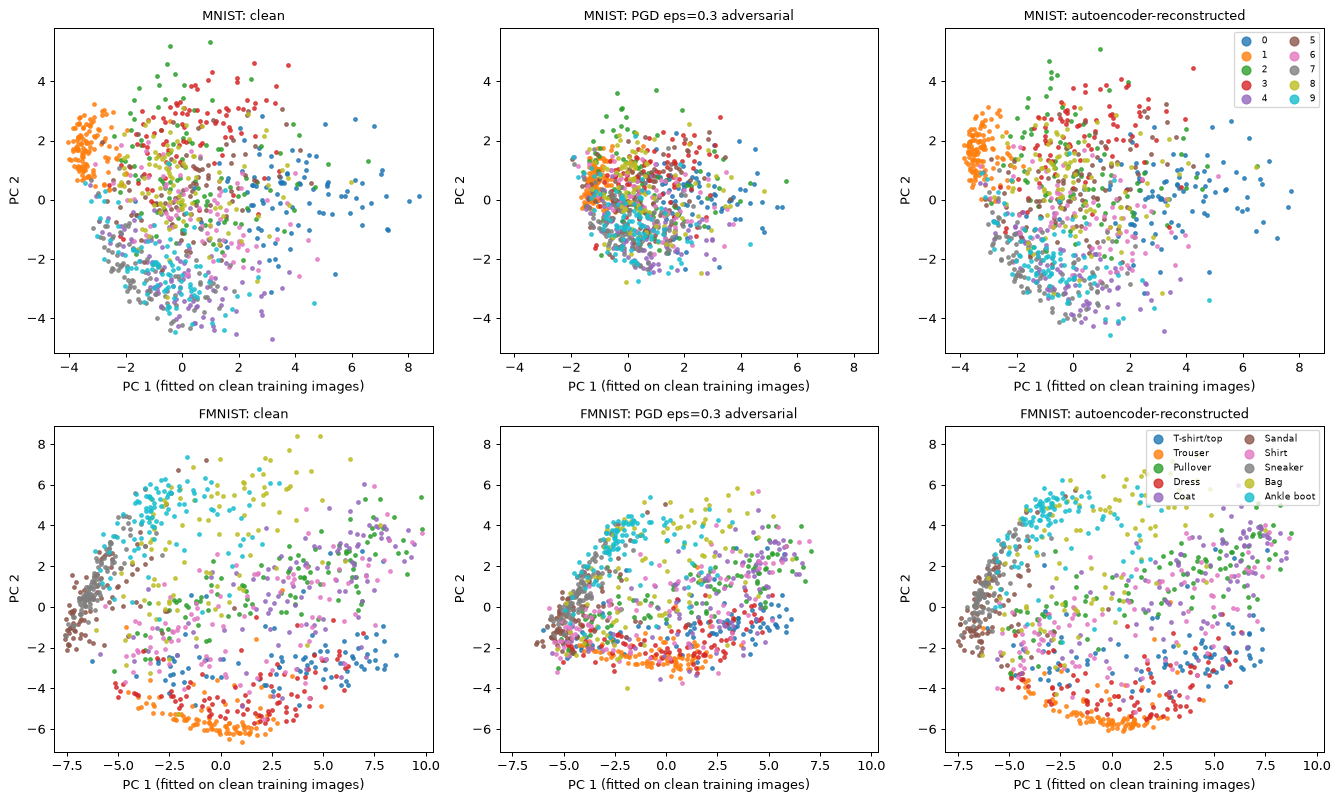

In [19]:
# Manifold view (paper: the autoencoder projects off-manifold adversarial inputs back to the data manifold):
# PCA fitted on clean TRAINING images; clean, PGD(0.3) adversarial and reconstructed versions of the same attacked test images, coloured by true class
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for r, ds in enumerate(DATASETS):
    d = DATA[ds]; y = ATT[ds]["y"].numpy()
    fit_idx = torch.randperm(len(d["ytr"]), generator=torch.Generator().manual_seed(SEED))[:N_PCA_FIT]
    pca = PCA(n_components=2, random_state=SEED).fit(d["Xtr"][fit_idx].numpy())
    adv = ADV[(ds, "PGD", EPS_SHOW)]
    sets = [("clean", ATT[ds]["X"]), (f"PGD eps={EPS_SHOW} adversarial", adv), ("autoencoder-reconstructed", purify(ds, adv))]
    allp = np.concatenate([pca.transform(s.numpy()) for _, s in sets]); lim = (allp.min(0) - 0.5, allp.max(0) + 0.5)
    for c, (title, S_) in enumerate(sets):
        P = pca.transform(S_.numpy()); ax = axes[r, c]
        for k in range(10):
            m = y == k; ax.scatter(P[m, 0], P[m, 1], s=8, alpha=0.8, color=plt.cm.tab10(k), label=CLASS_NAMES[ds][k])
        ax.set_xlim(lim[0][0], lim[1][0]); ax.set_ylim(lim[0][1], lim[1][1]); ax.set_title(f"{ds}: {title}", fontsize=10)
        ax.set_xlabel("PC 1 (fitted on clean training images)"); ax.set_ylabel("PC 2")
        if c == 2: ax.legend(markerscale=2.5, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()


## 6. Classical baselines on the same images

A fair question is whether the quantum model is special. The same attacked test images are used for a small classical CNN (attacked with its *own* gradient, and also with images crafted on the quantum model),
for a random forest and for an RBF-SVM (no gradients: they only see the images crafted on QVC100, i.e. transfer attacks). The **same autoencoder** (trained only on QVC100 attacks) is applied in front of each model, which also tests
whether the defence is specific to the quantum classifier. Training sizes are in the configuration cell.


MNIST: clean accuracy on 10000 test images: CNN 97.5 %, RF(15000 train) 95.6 %, SVC-rbf(10000 train) 95.9 %


FMNIST: clean accuracy on 10000 test images: CNN 86.2 %, RF(15000 train) 86.0 %, SVC-rbf(10000 train) 85.3 %


dataset                  MNIST       FMNIST      
attack (eps=0.3)          FGSM   PGD   FGSM   PGD
CNN clean                 97.1  97.1   87.5  87.5
CNN, own-gradient attack   1.0   0.0    0.6   0.0
CNN own attack + AE       36.7  34.7   19.8  23.6
CNN, QVC-crafted          67.2  67.5   19.7  17.4
CNN QVC-crafted + AE      89.9  90.4   73.9  70.4
RF clean                  95.5  95.5   87.3  87.3
RF, QVC-crafted           17.2  14.7   14.8  14.7
RF QVC-crafted + AE       80.7  82.6   69.4  65.6
SVC clean                 95.6  95.6   86.7  86.7
SVC, QVC-crafted          49.5  41.8   31.8  26.6
SVC QVC-crafted + AE      89.9  91.1   77.4  76.3
QVC100 (white-box)         0.0   0.0    0.0   0.0
QVC100 + AE               76.8  78.7   64.4  62.1

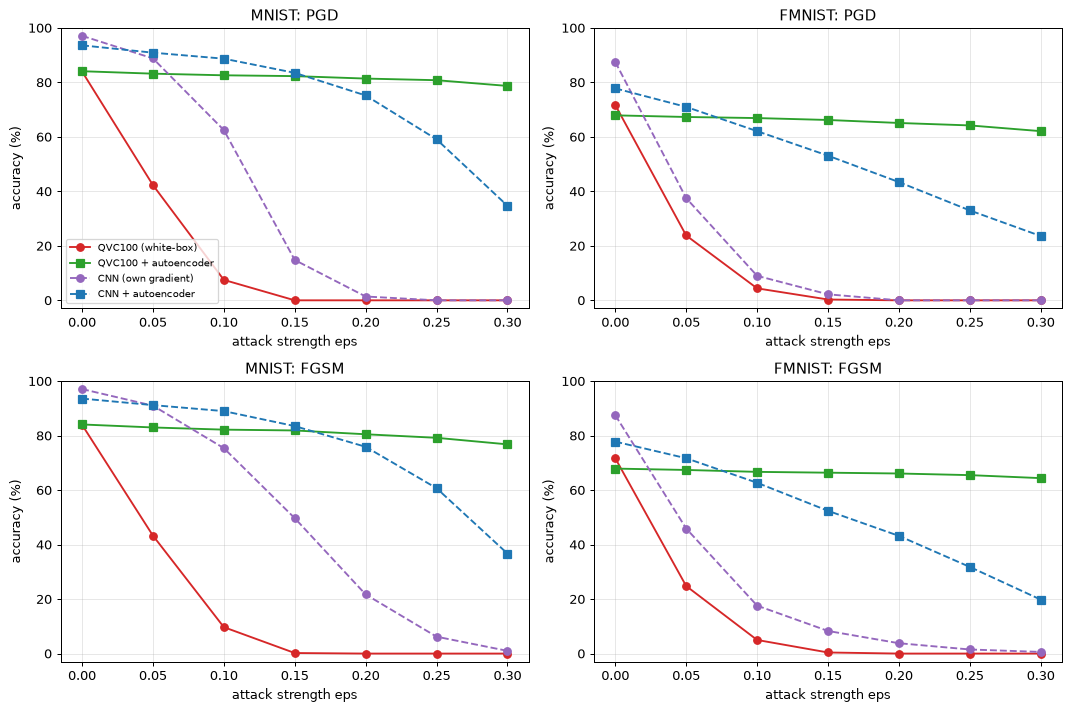

In [20]:
# Classical baselines on the SAME images (and the same attacked test images): a small CNN (white-box attackable, defended by the SAME autoencoder),
# a random forest and an RBF-SVM (no gradients: they only see the adversarial images crafted on the quantum model, i.e. transfer attacks).
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 16, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.Flatten(), nn.Linear(32 * 7 * 7, 64), nn.ReLU(), nn.Linear(64, 10))
    def forward(self, x):
        return self.net(x.reshape(-1, 1, 28, 28))

CLS = {}
t0 = time.time()
for ds in DATASETS:
    d = DATA[ds]; g = torch.Generator().manual_seed(SEED)
    torch.manual_seed(SEED)
    cnn = SmallCNN(); opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
    sub = torch.randperm(len(d["ytr"]), generator=g)[:N_CNN_TRAIN]
    for ep in range(CNN_EPOCHS):
        order = sub[torch.randperm(len(sub), generator=g)]
        for i in range(0, len(order), 128):
            b = order[i:i + 128]
            loss = F.cross_entropy(cnn(d["Xtr"][b]), d["ytr"][b]); opt.zero_grad(); loss.backward(); opt.step()
    cnn.eval()
    rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1).fit(d["Xtr"][:N_RF].numpy(), d["ytr"][:N_RF].numpy())
    svc = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(d["Xtr"][:N_SVC].numpy(), d["ytr"][:N_SVC].numpy())
    CLS[ds] = dict(cnn=cnn, rf=rf, svc=svc)
    te = TEST_PERM[ds][:N_CLEAN_TEST]
    print(f"{ds}: clean accuracy on {len(te)} test images: CNN {100 * acc_of(lambda z: cnn(z), d['Xte'][te], d['yte'][te]):.1f} %, "
          f"RF({N_RF} train) {100 * rf.score(d['Xte'][te].numpy(), d['yte'][te].numpy()):.1f} %, SVC-rbf({N_SVC} train) {100 * svc.score(d['Xte'][te].numpy(), d['yte'][te].numpy()):.1f} %")
TIMES["classical baselines"] = time.time() - t0

def sk_acc(model, X, y):
    return float((model.predict(X.numpy()) == y.numpy()).mean())

rows, CNN_CURVE = [], {}
for ds in DATASETS:
    X, y = ATT[ds]["X"], ATT[ds]["y"]; cnn = CLS[ds]["cnn"]; f_cnn = lambda z, m=cnn: m(z)
    # white-box attacks on the CNN with its own gradient, and the same autoencoder (trained on QVC100 attacks) as defence
    for atk, fn in ATTACKS.items():
        for eps in EPS_LIST:
            xa = fn(f_cnn, X, y, eps)
            CNN_CURVE[(ds, atk, eps, "adv")] = acc_of(f_cnn, xa, y); CNN_CURVE[(ds, atk, eps, "rec")] = acc_of(f_cnn, purify(ds, xa), y)
    for atk in ATTACKS:
        xq = ADV[(ds, atk, EPS_SHOW)]                       # adversarial images crafted on the QUANTUM model
        row = {"dataset": ds, "attack (eps=%.1f)" % EPS_SHOW: atk,
               "CNN clean": 100 * acc_of(f_cnn, X, y),
               "CNN, own-gradient attack": 100 * CNN_CURVE[(ds, atk, EPS_SHOW, "adv")], "CNN own attack + AE": 100 * CNN_CURVE[(ds, atk, EPS_SHOW, "rec")],
               "CNN, QVC-crafted": 100 * acc_of(f_cnn, xq, y), "CNN QVC-crafted + AE": 100 * acc_of(f_cnn, purify(ds, xq), y),
               "RF clean": 100 * sk_acc(CLS[ds]["rf"], X, y), "RF, QVC-crafted": 100 * sk_acc(CLS[ds]["rf"], xq, y), "RF QVC-crafted + AE": 100 * sk_acc(CLS[ds]["rf"], purify(ds, xq), y),
               "SVC clean": 100 * sk_acc(CLS[ds]["svc"], X, y), "SVC, QVC-crafted": 100 * sk_acc(CLS[ds]["svc"], xq, y), "SVC QVC-crafted + AE": 100 * sk_acc(CLS[ds]["svc"], purify(ds, xq), y),
               f"{NAME_A} (white-box)": 100 * ACC[(ds, atk, "white", EPS_SHOW, "adv")], f"{NAME_A} + AE": 100 * ACC[(ds, atk, "white", EPS_SHOW, "rec")]}
        rows.append(row)
display(pd.DataFrame(rows).set_index(["dataset", "attack (eps=%.1f)" % EPS_SHOW]).round(1).T)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for r, atk in enumerate(("PGD", "FGSM")):
    for c, ds in enumerate(DATASETS):
        ax = axes[r, c]
        ax.plot(EPS_LIST, [100 * ACC[(ds, atk, "white", e, "adv")] for e in EPS_LIST], "o-", color="tab:red", label=f"{NAME_A} (white-box)")
        ax.plot(EPS_LIST, [100 * ACC[(ds, atk, "white", e, "rec")] for e in EPS_LIST], "s-", color="tab:green", label=f"{NAME_A} + autoencoder")
        ax.plot(EPS_LIST, [100 * CNN_CURVE[(ds, atk, e, "adv")] for e in EPS_LIST], "o--", color="tab:purple", label="CNN (own gradient)")
        ax.plot(EPS_LIST, [100 * CNN_CURVE[(ds, atk, e, "rec")] for e in EPS_LIST], "s--", color="tab:blue", label="CNN + autoencoder")
        ax.set_xlabel("attack strength eps"); ax.set_ylabel("accuracy (%)"); ax.set_title(f"{ds}: {atk}"); ax.grid(alpha=0.3); ax.set_ylim(-3, 100)
        if r == 0 and c == 0: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 7. Side-by-side comparison with the paper

The paper prints numbers only in its text (the plots have no values), so every claim of the introduction is checked here: numeric claims are *reproduced* when within 2 accuracy points of the paper (the project's rule),
*exceeded* or *not reached* with the gap otherwise (the sign is relative to the claim: for "accuracy drops to 0 %" a higher accuracy means the attack here is weaker); "near 0" claims are reproduced up to 5 %;
qualitative claims are checked against the notebook's own curves. The last rows record what cannot be compared.


In [21]:
# Side-by-side comparison with the paper. Numeric claims: "reproduced" if within 2 accuracy points (brief's rule), otherwise "exceeded" / "not reached"
# with the gap. "near 0" claims: reproduced if <= 5 %. Qualitative claims are tested as statements about the notebook's own curves.
E3 = EPS_LIST[-1]
a = lambda ds, atk, scen, e, kind: 100 * ACC[(ds, atk, scen, e, kind)]
clean = lambda ds, L: 100 * QVC[(ds, L)]["clean_acc"]

def v_num(ours, paper, better, tol=2.0):
    gap = ours - paper
    if abs(gap) <= tol: return "reproduced"
    return (f"exceeded ({gap:+.1f} points)" if (gap > 0) == (better == "higher") else f"not reached ({gap:+.1f} points)")
def v_zero(ours, thr=5.0):
    return "reproduced" if ours <= thr else f"not reached ({ours:.1f} % > {thr:.0f} %)"
def v_bool(ok):
    return "reproduced" if ok else "not reached"

depth_note = "" if not FAST_MODE else "  [FAST_MODE: shallow stand-in circuits]"
claims = []
def add(claim, paper, ours, verdict):
    claims.append({"claim (paper section / figure)": claim, "paper": paper, "this notebook": ours, "verdict": verdict})

add(f"{NAME_A} clean accuracy, MNIST (Fig. 3a)", "85 %", f"{clean('MNIST', LAYERS[0]):.1f} %", v_num(clean('MNIST', LAYERS[0]), 85, "higher"))
add(f"{NAME_A} clean accuracy, FMNIST (Fig. 3c)", "70 %", f"{clean('FMNIST', LAYERS[0]):.1f} %", v_num(clean('FMNIST', LAYERS[0]), 70, "higher"))
add(f"{NAME_B} clean accuracy, MNIST (Fig. 3b, black-box start)", "89 %", f"{clean('MNIST', LAYERS[1]):.1f} %", v_num(clean('MNIST', LAYERS[1]), 89, "higher"))
add(f"PGD white-box, MNIST, eps = {E3}: accuracy 'nearly 0'", "~0 %", f"{a('MNIST', 'PGD', 'white', E3, 'adv'):.1f} %", v_zero(a('MNIST', 'PGD', 'white', E3, 'adv')))
add(f"PGD white-box, FMNIST, eps = {E3}: accuracy falls to ~0 (Fig. 3c)", "~0 %", f"{a('FMNIST', 'PGD', 'white', E3, 'adv'):.1f} %", v_zero(a('FMNIST', 'PGD', 'white', E3, 'adv')))
add(f"PGD black-box ({NAME_A} -> {NAME_B}), MNIST, eps = {E3}", "15 %", f"{a('MNIST', 'PGD', 'black', E3, 'adv'):.1f} %", v_num(a('MNIST', 'PGD', 'black', E3, 'adv'), 15, "lower"))
add(f"FGSM white-box, MNIST, eps = {E3} (Fig. S2)", "0 %", f"{a('MNIST', 'FGSM', 'white', E3, 'adv'):.1f} %", v_num(a('MNIST', 'FGSM', 'white', E3, 'adv'), 0, "lower"))
add(f"FGSM white-box, FMNIST, eps = {E3} (Fig. S2)", "0 %", f"{a('FMNIST', 'FGSM', 'white', E3, 'adv'):.1f} %", v_num(a('FMNIST', 'FGSM', 'white', E3, 'adv'), 0, "lower"))
add(f"autoencoder recovery, FGSM white-box, MNIST, eps = {E3}", "80 %", f"{a('MNIST', 'FGSM', 'white', E3, 'rec'):.1f} %", v_num(a('MNIST', 'FGSM', 'white', E3, 'rec'), 80, "higher"))
add(f"autoencoder recovery, FGSM white-box, FMNIST, eps = {E3}", "65 %", f"{a('FMNIST', 'FGSM', 'white', E3, 'rec'):.1f} %", v_num(a('FMNIST', 'FGSM', 'white', E3, 'rec'), 65, "higher"))

bb, wb = a('MNIST', 'PGD', 'black', E3, 'adv'), a('MNIST', 'PGD', 'white', E3, 'adv')
add("black-box PGD is less severe than white-box PGD (MNIST, eps max)", "accuracy 15 % vs ~0 %", f"{bb:.1f} % vs {wb:.1f} %", v_bool(bb > wb))
early = lambda ds: a(ds, 'PGD', 'white', EPS_LIST[1], 'adv') / max(a(ds, 'PGD', 'white', 0.0, 'adv'), 1e-9)
d_share = early('MNIST') - early('FMNIST')
add(f"FMNIST accuracy falls faster than MNIST under white-box PGD (share of clean accuracy kept at eps = {EPS_LIST[1]})", "FMNIST drops more rapidly",
    f"MNIST keeps {100 * early('MNIST'):.0f} %, FMNIST keeps {100 * early('FMNIST'):.0f} %",
    "reproduced" if d_share > 0.02 else ("cannot be distinguished (|difference| <= 2 points)" if d_share >= -0.02 else "not reached"))
fm_bb = a('FMNIST', 'PGD', 'black', E3, 'adv') / max(a('FMNIST', 'PGD', 'black', 0.0, 'adv'), 1e-9)
add("black-box PGD also transfers on FMNIST ('comparable trend': at least half of the clean accuracy lost at eps max)", "comparable trend", f"FMNIST keeps {100 * fm_bb:.0f} % of its clean accuracy", v_bool(fm_bb < 0.5))
cells = [(ds, atk, scen, e) for ds in DATASETS for atk in ATTACKS for scen in ("white", "black") for e in EPS_LIST[1:]]
tgt = lambda ds, scen: LAYERS[0] if scen == "white" else LAYERS[1]
hurt = [c for c in cells if clean(c[0], tgt(c[0], c[2])) - a(*c, 'adv') > 5]       # settings where the attack costs more than 5 accuracy points
better = sum(a(*c, 'rec') > a(*c, 'adv') for c in hurt)
add("reconstructed images are classified better than adversarial ones wherever the attack costs more than 5 accuracy points (2 datasets x 2 attacks x 2 scenarios x 6 eps)", "significant recovery in all cases",
    f"{better} of {len(hurt)} such cells", v_bool(better == len(hurt)))
gain = np.mean([a(ds, atk, scen, E3, 'rec') - a(ds, atk, scen, E3, 'adv') for ds in DATASETS for atk in ATTACKS for scen in ("white", "black")])
add("... and the recovery is substantial at the strongest attack (mean gain over the 8 settings at eps max; our threshold: at least 20 accuracy points)", "'substantial'",
    f"{gain:+.1f} points", v_bool(gain >= 20))
add("accuracy curves of Fig. 3 / Fig. S2 at the intermediate eps values", "bar/line plots only, no numbers in the text", "see the figures above", "cannot be checked (numerically)")
add("training the full 60 000-image set for 20 epochs with 4700 Adam steps; hardware: one NVIDIA GPU", "paper budget", f"{TRAIN_STEPS} steps x batch {BATCH} on CPU", "not reached (compute budget; documented deviation)")
cmp_df = pd.DataFrame(claims)
display(cmp_df)
print("verdict counts:", cmp_df["verdict"].str.split(" ").str[0].value_counts().to_dict())
print("\nautoencoder-seed spread (recovered accuracy, white-box, eps max):")
for (ds, atk), v in SEEDS_REC.items():
    print(f"  {ds} {atk}: {100 * np.mean(v):.1f} +- {100 * np.std(v):.1f} % over {len(v)} seed(s)")
print("\nwall-clock seconds of the heavy stages:", {k: round(v) for k, v in TIMES.items()}, "| total", round(sum(TIMES.values()) / 60, 1), "min")


,claim (paper section / figure),paper,this notebook,verdict
0,"QVC100 clean accuracy, MNIST (Fig. 3a)",85 %,82.7 %,not reached (-2.3 points)
1,"QVC100 clean accuracy, FMNIST (Fig. 3c)",70 %,69.7 %,reproduced
2,"QVC200 clean accuracy, MNIST (Fig. 3b, black-box start)",89 %,82.8 %,not reached (-6.2 points)
3,"PGD white-box, MNIST, eps = 0.3: accuracy 'nearly 0'",~0 %,0.0 %,reproduced
4,"PGD white-box, FMNIST, eps = 0.3: accuracy falls to ~0 (Fig. 3c)",~0 %,0.0 %,reproduced
5,"PGD black-box (QVC100 -> QVC200), MNIST, eps = 0.3",15 %,33.3 %,not reached (+18.3 points)
6,"FGSM white-box, MNIST, eps = 0.3 (Fig. S2)",0 %,0.0 %,reproduced
7,"FGSM white-box, FMNIST, eps = 0.3 (Fig. S2)",0 %,0.0 %,reproduced
8,"autoencoder recovery, FGSM white-box, MNIST, eps = 0.3",80 %,76.8 %,not reached (-3.2 points)
9,"autoencoder recovery, FGSM white-box, FMNIST, eps = 0.3",65 %,64.4 %,reproduced


verdict counts: {'reproduced': 11, 'not': 5, 'cannot': 1}

autoencoder-seed spread (recovered accuracy, white-box, eps max):
  MNIST FGSM: 76.9 +- 0.1 % over 2 seed(s)
  MNIST PGD: 78.8 +- 0.2 % over 2 seed(s)
  FMNIST FGSM: 63.7 +- 0.7 % over 2 seed(s)
  FMNIST PGD: 62.9 +- 0.8 % over 2 seed(s)

wall-clock seconds of the heavy stages: {'train MNIST QVC100': 368, 'train MNIST QVC200': 708, 'train FMNIST QVC100': 181, 'train FMNIST QVC200': 383, 'attacks MNIST': 42, 'attacks FMNIST': 64, 'autoencoder MNIST': 470, 'autoencoder FMNIST': 389, 'defence evaluation': 31, 'classical baselines': 1225} | total 64.4 min


## 8. Reading the paper critically

(The notes below were written after running this notebook once in full mode, `FAST_MODE = False`: QVC100 / QVC200, seed 42, 78 minutes on a shared 4-core CPU; numbers are quoted from the tables above and will move by a few points with other seeds, other attacked images or the FAST settings.)

**What the run found.** Of the 17 rows of the comparison table, 11 are *reproduced*, 5 *not reached* and 1 cannot be checked. The qualitative story of the paper holds: both attacks drive the undefended QVC100 to 0 % (white-box PGD and FGSM at `eps = 0.3` for both datasets; in this run already at `eps = 0.15`), the images crafted on QVC100 transfer to QVC200 (accuracy at `eps = 0.3`: 33 % under PGD on MNIST, 23 % on FMNIST), and the classical autoencoder gives most of the accuracy back (white-box FGSM at `eps = 0.3`: 76.8 % on MNIST against the paper's 80 %, 64.4 % on FMNIST against 65 %; PGD: 78.7 % and 62.1 %; mean gain at `eps = 0.3` over the eight settings: +55.9 points, and the reconstruction beats the adversarial image in all 46 cells where the attack costs more than 5 points). The autoencoder-seed spread is small (0.1 to 0.8 points over two seeds).
The five "not reached" rows are: QVC100 on MNIST clean (82.7 % vs 85 %, a 2.3-point gap, inside the noise of 10 000 test images and one training run), QVC200 on MNIST clean (82.8 % vs 89 %), black-box PGD on MNIST (33 % vs 15 %), the white-box FGSM recovery on MNIST (76.8 % vs 80 %), and the compute budget row, which is a deviation, not a result.

**1. The compute budget is the largest caveat.** The paper trains for 4 700 Adam steps of batch 256 on a GPU; here each classifier sees 6 400 images once (0.11 epoch, 100 steps of batch 64, learning rate raised from 0.005 to 0.02 to compensate), and the loss curves are still falling when training stops. QVC200 did not reach the 89 % the paper reports (82.8 %); it is not better than QVC100 here, which may also explain why the black-box transfer is *weaker* for the attacker than in the paper (33 % vs 15 % left on MNIST), for example if the paper's two circuits are better trained and therefore more alike; this is a hypothesis, not something the run tests. The paper does not say how many PGD steps it used; with exact gradients our 10-step PGD is already stronger than the numbers in the text require, so "attack strength" is not what separates the two black-box results.

**2. The defence is evaluated against a non-adaptive attacker.** The adversarial images are crafted on the *undefended* quantum circuit and only afterwards sent through the autoencoder, so the attacker does not know the defence. Preprocessing defences built from autoencoders are known to be vulnerable to attackers who differentiate through them (Carlini and Wagner, 2017, on MagNet), and nothing in the paper tests this. Section 6 of this notebook hints at how brittle the recovery is: the same autoencoder, trained on QVC100 attacks, gives a classical CNN under *its own* gradient attack only 37 % / 35 % (MNIST, FGSM / PGD) and 20 % / 24 % (FMNIST) at `eps = 0.3`, much less than the 77-79 % it restores for the quantum model, because the CNN's perturbation does not look like the perturbations the autoencoder was trained on. The recovery is therefore tied to the attack distribution seen in training (one mixture of FGSM and PGD at six strengths, our choice since the paper does not give one). Exercise 1 is the adaptive-attack test.

**3. What is quantum here, and what is not.** The autoencoder is a purely classical denoiser; applied to a classical CNN, a random forest and an RBF-SVM attacked with the QVC100 images it recovers 23 to 64 points as well (for example RF: 15-17 % under the QVC-crafted images, 66-83 % after the autoencoder). The defence therefore says nothing specific about quantum models. The undefended QVC is also the *least accurate* model on the identical data (the classical models got much larger training budgets, so this is not a fair accuracy contest: 82.7 % vs 97.5 % for a small CNN, 95.6 % for the random forest and 95.9 % for the SVM on MNIST; 69.7 % vs 86.2 / 86.0 / 85.3 % on FMNIST), so "QVC-CED" does not compete with simply using a classical classifier plus the same denoiser (CNN + autoencoder: 90 % on MNIST and 70-74 % on FMNIST under the QVC-crafted images).

**4. A hidden cost.** The reconstructed `eps = 0` point shows what the defence costs on clean data: nothing on MNIST (84.1 % vs 84.0 %), but 3.8 points on FMNIST (67.9 % vs 71.7 %), because a 20-number bottleneck cannot hold textures. The paper plots this point but does not discuss it.

**5. "Imperceptible" perturbations.** The paper says the perturbations are "often imperceptible to the human eye". The Fig. 2 analogue above shows that an L-infinity ball of `eps = 0.3` on `[0, 1]` pixels is plainly visible; the near-total collapse of the white-box accuracy already at `eps = 0.1` to `0.15` (8 % and 0 % under PGD on MNIST) is the more informative regime, and the paper's curves only show the quoted points.

**6. Statistics.** The attacked set is 1 000 images (binomial standard error about 1.2 points at 80 %), the autoencoder has two seeds and each classifier one training seed, so the 2-point rule of the verdict table is at the edge of what this run can resolve; gaps of a few points in the clean accuracies are not evidence about the paper.

**7. What cannot be checked.** The paper's figures carry no numbers (only the points quoted in the text can be compared), no code or weights were released, and the circuit's gate order, entangler layout, initialisation, PGD step count, autoencoder training mixture and batch sizes are unspecified; all of them are marked `# CHOICE:` in the code. The equivalence assertions show that the simulator is exact for the *assumed* circuit, not that the assumed circuit is the paper's.


## 9. Exercises

1. **Attack the defence.** The autoencoder never sees the attacker, so this is a *gray-box* test. Craft PGD through the *composition* `QVC(AE(x))` (differentiate through the autoencoder as well) and plot Fig. 3 again. How much of the recovered accuracy survives an adaptive attacker?
2. **Training budget.** Increase `TRAIN_STEPS` from 100 to 400 and set `BATCH = 256`, `LR = 0.005` as in the paper. How do clean accuracy, robustness at `eps = 0.1` and the transfer to QVC200 change?
3. **Attack mixture.** Train the autoencoder only on FGSM images (or only on `eps <= 0.15`). Which attack/strength combinations generalise, which break?
4. **Circuit assumptions.** Change the CZ chain to a ring, or swap `Rot` for `RX RY RZ` in `make_qnode` and `run_circuit`'s block structure (only the RZ/RY factorisation is hard-wired in the fast simulator, so use PennyLane for the new variant). Does the robustness of the undefended classifier change?
5. **Beyond the paper.** Replace the autoencoder by a plain Gaussian blur or by a PCA projection onto 20 components. Is a *learned* denoiser needed, or is any low-dimensional projection enough?
